In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# ===== NAB path setup (runs anywhere: finds NAB-master by itself) =====
import os, json
from pathlib import Path

def _find_nab_root():
    """Look for a folder called NAB-master in the current folder or any parent folder."""
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        for cand in (folder / "NAB-master", folder):
            if cand.name == "NAB-master" and (cand / "data").is_dir() and (cand / "labels").is_dir():
                return cand
    raise FileNotFoundError(
        f"Could not find a NAB-master folder (with 'data' and 'labels') starting from {here}. "
        "Open the SentinelAI folder in VS Code, or set NAB_ROOT by hand below.")

NAB_ROOT   = _find_nab_root()           # e.g. Desktop/SentinalAI/NAB-master
DATA_DIR   = NAB_ROOT / "data"          # realKnownCause, realAWSCloudwatch, artificial...
LABELS_DIR = NAB_ROOT / "labels"        # combined_labels.json, combined_windows.json, ...

# Where this notebook writes its results (created next to the notebook, not inside NAB-master)
OUTPUT_ROOT = Path.cwd() / "NAB_outputs"
PREPARED    = str(OUTPUT_ROOT / "prepared")
OUT         = str(OUTPUT_ROOT / "final")      # models + configs for the API end up here
os.makedirs(PREPARED, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

# Index every CSV / JSON by file name, so a file is found wherever it sits inside NAB-master
_CSV_INDEX  = {p.name: p for p in DATA_DIR.rglob("*.csv")}
_JSON_INDEX = {p.name: p for p in LABELS_DIR.rglob("*.json")}

def find_data(name):
    """Path of a NAB data CSV, e.g. find_data('nyc_taxi.csv')."""
    name = os.path.basename(str(name))
    if name not in _CSV_INDEX:
        raise FileNotFoundError(f"{name} not found anywhere under {DATA_DIR}")
    return _CSV_INDEX[name]

def find_label(name):
    """Path of a NAB label file, e.g. find_label('combined_labels.json') (also searches labels/raw)."""
    name = os.path.basename(str(name))
    if name not in _JSON_INDEX:
        raise FileNotFoundError(f"{name} not found anywhere under {LABELS_DIR}")
    return _JSON_INDEX[name]

# The nine files this project uses (the notebook was written for exactly these)
NINE_CSVS = [
    "art_daily_jumpsdown.csv", "art_daily_jumpsup.csv", "art_daily_small_noise.csv",
    "cpu_utilization_asg_misconfiguration.csv", "ec2_cpu_utilization_5f5533.csv",
    "ec2_disk_write_bytes_1ef3de.csv", "ec2_network_in_5abac7.csv",
    "ec2_request_latency_system_failure.csv", "machine_temperature_system_failure.csv",
]

print("NAB_ROOT :", NAB_ROOT)
print("Outputs  :", OUTPUT_ROOT)
missing = [n for n in NINE_CSVS if n not in _CSV_INDEX]
print("All nine data files found" if not missing else f"MISSING data files: {missing}")
for n in ["combined_labels.json", "combined_windows.json", "combined_windows_tiny.json",
          "known_labels_v1.0.json", "AL_labels_v1.0.json", "CB_labels_v1.0.json", "SA_labels_v1.0.json"]:
    print(f"  {n:32s}", "found" if n in _JSON_INDEX else "MISSING")


NAB_ROOT : C:\Users\Lenovo\Desktop\SentinalAI\NAB-master
Outputs  : c:\Users\Lenovo\Desktop\SentinalAI\NAB_outputs
All nine data files found
  combined_labels.json             found
  combined_windows.json            found
  combined_windows_tiny.json       found
  known_labels_v1.0.json           found
  AL_labels_v1.0.json              found
  CB_labels_v1.0.json              found
  SA_labels_v1.0.json              found


In [3]:
df = pd.read_csv(find_data("machine_temperature_system_failure.csv"))

In [4]:
df.shape

(22695, 2)

In [5]:
df.head()

,timestamp,value
0,2013-12-02 21:15:00,73.967322
1,2013-12-02 21:20:00,74.935882
2,2013-12-02 21:25:00,76.124162
3,2013-12-02 21:30:00,78.140707
4,2013-12-02 21:35:00,79.329836


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22695 entries, 0 to 22694
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  22695 non-null  object 
 1   value      22695 non-null  float64
dtypes: float64(1), object(1)
memory usage: 354.7+ KB


In [7]:
time="2013-12-02 21:15:00"
time.split(" ")

['2013-12-02', '21:15:00']

In [8]:
# Function to get the Date (the first part of the split)
def get_date(text):
    return str(text).split()[0]

# Function to get the Time (the second part of the split)
def get_time(text):
    return str(text).split()[1]


In [9]:
df['date']=df['timestamp'].apply(get_date)
df['time']=df['timestamp'].apply(get_time)

In [10]:
df

,timestamp,value,date,time
0,2013-12-02 21:15:00,73.967322,2013-12-02,21:15:00
1,2013-12-02 21:20:00,74.935882,2013-12-02,21:20:00
2,2013-12-02 21:25:00,76.124162,2013-12-02,21:25:00
3,2013-12-02 21:30:00,78.140707,2013-12-02,21:30:00
4,2013-12-02 21:35:00,79.329836,2013-12-02,21:35:00
...,...,...,...,...
22690,2014-02-19 15:05:00,98.185415,2014-02-19,15:05:00
22691,2014-02-19 15:10:00,97.804168,2014-02-19,15:10:00
22692,2014-02-19 15:15:00,97.135468,2014-02-19,15:15:00
22693,2014-02-19 15:20:00,98.056852,2014-02-19,15:20:00


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["timestamp"].is_monotonic_increasing

False

In [13]:
df["timestamp"].isna().sum()

np.int64(0)

In [14]:
df["timestamp"].duplicated().sum()

np.int64(12)

In [15]:
df=df.drop_duplicates(subset='timestamp',keep='first')

In [16]:
df['value'].duplicated().sum()

np.int64(0)

In [17]:
df=df.sort_values(by='timestamp')
df['timestamp']=df['timestamp'].astype('datetime64[ns]')
df["timestamp"].diff().value_counts().head()

timestamp
0 days 00:05:00    22682
Name: count, dtype: int64

In [18]:
df.describe()

,timestamp,value
count,22683,22683.000000
mean,2014-01-11 06:20:00,85.922359
min,2013-12-02 21:15:00,2.084721
25%,2013-12-22 13:47:30,83.074740
50%,2014-01-11 06:20:00,89.403332
75%,2014-01-30 22:52:30,94.015731
max,2014-02-19 15:25:00,108.510543
std,NaN,13.749365


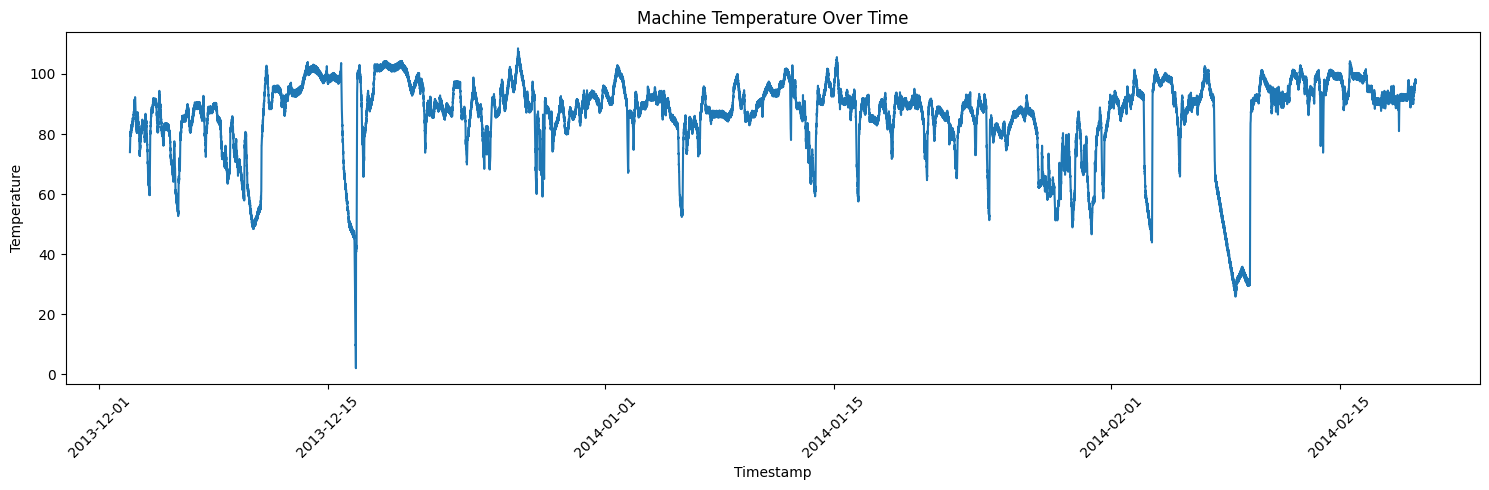

In [19]:
plt.figure(figsize=(15, 5))

plt.plot(df["timestamp"], df["value"])

plt.title("Machine Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
# Filter for rows where the year is 2013 and month is 12 (December)
dec_df = df[(df['timestamp'].dt.year == 2013) & (df['timestamp'].dt.month == 12)]

# Show the summary statistics for just this month
dec_df['value'].describe()


count    8385.000000
mean       86.790447
std        12.923980
min         2.084721
25%        82.278758
50%        89.011082
75%        95.492450
max       108.510543
Name: value, dtype: float64

In [21]:
window_size = 288  # 24 hours of data if sampled every 5 minutes

df["rolling_mean"] = df["value"].rolling(window=window_size, min_periods=1).mean()
df["rolling_std"] = df["value"].rolling(window=window_size, min_periods=1).std()

# Calculate Z-Score (added 1e-5 to prevent division-by-zero on flatlines)
df["z_score"] = (df["value"] - df["rolling_mean"]) / (df["rolling_std"] + 1e-5)

# Step 4: Create the final anomaly flag (1 for anomaly, 0 for normal)
df["is_anomaly"] = (df["z_score"].abs() > 3.0).astype(int)

# Step 5: Check your results
print(df[["timestamp", "value", "z_score", "is_anomaly"]].head())

            timestamp      value   z_score  is_anomaly
0 2013-12-02 21:15:00  73.967322       NaN           0
1 2013-12-02 21:20:00  74.935882  0.707096           0
2 2013-12-02 21:25:00  76.124162  1.032164           0
3 2013-12-02 21:30:00  78.140707  1.306896           0
4 2013-12-02 21:35:00  79.329836  1.275257           0


In [22]:
# Counts consecutive anomalies. Resets to 0 when data goes back to normal.
df['anomaly_duration_count'] = df['is_anomaly'].groupby((df['is_anomaly'] == 0).cumsum()).cumsum()


In [23]:
# Calculates the raw change from the previous data point
df['temperature_velocity'] = df['value'].diff().fillna(0)


In [24]:
# Percentage difference from the rolling mean
df['pct_above_baseline'] = ((df['value'] - df['rolling_mean']) / (df['rolling_mean'] + 1e-5)) * 100


In [25]:
df.columns

Index(['timestamp', 'value', 'date', 'time', 'rolling_mean', 'rolling_std',
       'z_score', 'is_anomaly', 'anomaly_duration_count',
       'temperature_velocity', 'pct_above_baseline'],
      dtype='object')

In [26]:
pop=pd.read_csv(find_data("cpu_utilization_asg_misconfiguration.csv"))

In [27]:
pop.shape

(18050, 2)

In [28]:
pop.head()

,timestamp,value
0,2014-05-14 01:14:00,85.835
1,2014-05-14 01:19:00,88.167
2,2014-05-14 01:24:00,44.595
3,2014-05-14 01:29:00,56.282
4,2014-05-14 01:34:00,36.534


In [29]:
# Function to get the Date (the first part of the split)
def get_date(text):
    return str(text).split()[0]

# Function to get the Time (the second part of the split)
def get_time(text):
    return str(text).split()[1]


In [30]:
pop['date']=pop['timestamp'].apply(get_date)
pop['time']=pop['timestamp'].apply(get_time)

In [31]:
pop.columns

Index(['timestamp', 'value', 'date', 'time'], dtype='object')

In [32]:
pop=pop.sort_values(by='timestamp')

pop['timestamp']=pop['timestamp'].astype('datetime64[ns]')
pop["timestamp"].diff().value_counts().head()

timestamp
0 days 00:05:00    18049
Name: count, dtype: int64

In [33]:
pop['timestamp'].duplicated().sum()

np.int64(0)

In [34]:
pop['value'].duplicated().sum()

np.int64(10900)

In [35]:
pop['timestamp'].is_monotonic_increasing

True

In [36]:
pop['timestamp'].isna().sum()

np.int64(0)

In [37]:
pop.columns

Index(['timestamp', 'value', 'date', 'time'], dtype='object')

In [38]:
pop.describe()

,timestamp,value
count,18050,18050.000000
mean,2014-06-14 09:16:30,38.282756
min,2014-05-14 01:14:00,11.529000
25%,2014-05-29 17:15:15,30.789000
50%,2014-06-14 09:16:30,32.001000
75%,2014-06-30 01:17:45,35.660500
max,2014-07-15 17:19:00,100.000000
std,NaN,15.639294


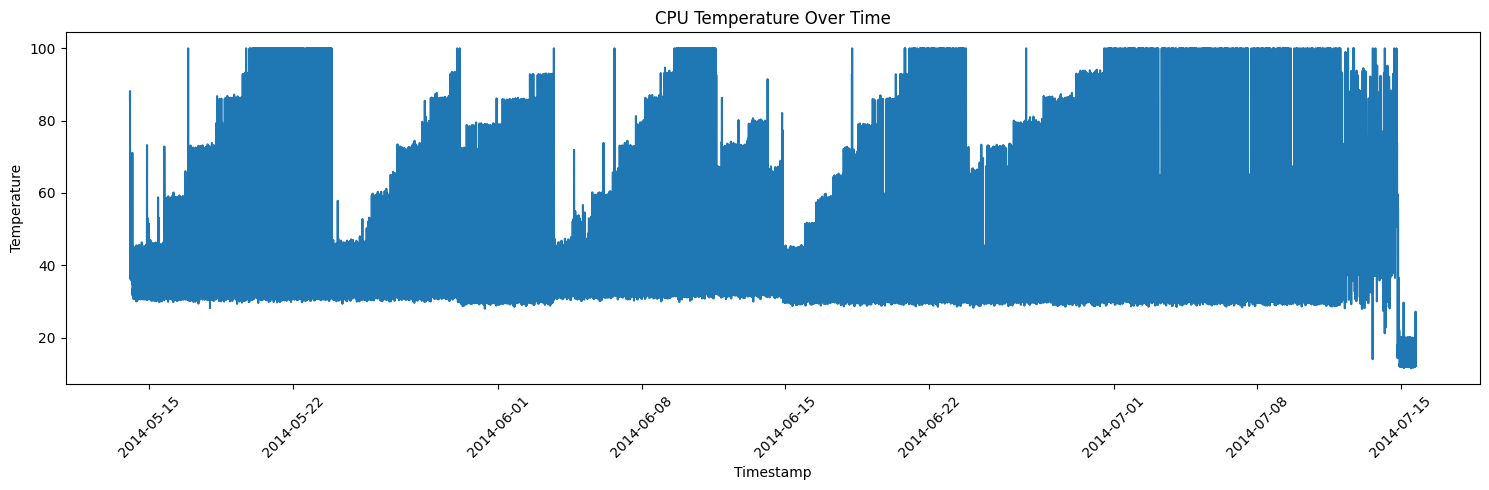

In [39]:
plt.figure(figsize=(15, 5))

plt.plot(pop["timestamp"], pop["value"])

plt.title("CPU Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
window_size = 288  # 24 hours of data if sampled every 5 minutes

pop["rolling_mean"] = pop["value"].rolling(window=window_size, min_periods=1).mean()
pop["rolling_std"] = pop["value"].rolling(window=window_size, min_periods=1).std()

# Calculate Z-Score (added 1e-5 to prevent division-by-zero on flatlines)
pop["z_score"] = (pop["value"] - pop["rolling_mean"]) / (pop["rolling_std"] + 1e-5)

# Step 4: Create the final anomaly flag (1 for anomaly, 0 for normal)
pop["is_anomaly"] = (pop["z_score"].abs() > 3.0).astype(int)

# Step 5: Check your results
print(pop[["timestamp", "value", "z_score", "is_anomaly"]].head())

            timestamp   value   z_score  is_anomaly
0 2014-05-14 01:14:00  85.835       NaN           0
1 2014-05-14 01:19:00  88.167  0.707102           0
2 2014-05-14 01:24:00  44.595 -1.153393           0
3 2014-05-14 01:29:00  56.282 -0.574153           0
4 2014-05-14 01:34:00  36.534 -1.088911           0


In [41]:
# Counts consecutive anomalies. Resets to 0 when data goes back to normal.
pop['anomaly_duration_count'] = pop['is_anomaly'].groupby((pop['is_anomaly'] == 0).cumsum()).cumsum()


In [42]:
# Calculates the raw change from the previous data point
pop['temperature_velocity'] = pop['value'].diff().fillna(0)


In [43]:
# Percentage difference from the rolling mean
pop['pct_above_baseline'] = ((pop['value'] - pop['rolling_mean']) / (pop['rolling_mean'] + 1e-5)) * 100


In [44]:
pop.columns

Index(['timestamp', 'value', 'date', 'time', 'rolling_mean', 'rolling_std',
       'z_score', 'is_anomaly', 'anomaly_duration_count',
       'temperature_velocity', 'pct_above_baseline'],
      dtype='object')

In [45]:
lol=pd.read_csv(find_data("ec2_request_latency_system_failure.csv"))

In [46]:
lol.shape

(4032, 2)

In [47]:
lol.head()

,timestamp,value
0,2014-03-07 03:41:00,45.868
1,2014-03-07 03:46:00,47.606
2,2014-03-07 03:51:00,42.580
3,2014-03-07 03:56:00,46.030
4,2014-03-07 04:01:00,44.992


In [48]:
# Function to get the Date (the first part of the split)
def get_date(text):
    return str(text).split()[0]

# Function to get the Time (the second part of the split)
def get_time(text):
    return str(text).split()[1]


In [49]:
lol['date']=lol['timestamp'].apply(get_date)
lol['time']=lol['timestamp'].apply(get_time)

In [50]:
lol.columns

Index(['timestamp', 'value', 'date', 'time'], dtype='object')

In [51]:
lol['timestamp'].isna().sum()

np.int64(0)

In [52]:
lol['value'].isna().sum()

np.int64(0)

In [53]:
lol['timestamp'].duplicated().sum()

np.int64(11)

In [54]:
lol.drop_duplicates(subset=['timestamp'],keep='first')

,timestamp,value,date,time
0,2014-03-07 03:41:00,45.868,2014-03-07,03:41:00
1,2014-03-07 03:46:00,47.606,2014-03-07,03:46:00
2,2014-03-07 03:51:00,42.580,2014-03-07,03:51:00
3,2014-03-07 03:56:00,46.030,2014-03-07,03:56:00
4,2014-03-07 04:01:00,44.992,2014-03-07,04:01:00
...,...,...,...,...
4027,2014-03-21 03:21:00,25.352,2014-03-21,03:21:00
4028,2014-03-21 03:26:00,38.216,2014-03-21,03:26:00
4029,2014-03-21 03:31:00,22.864,2014-03-21,03:31:00
4030,2014-03-21 03:36:00,66.260,2014-03-21,03:36:00


In [55]:
lol.sort_values(by='timestamp')
lol['timestamp']=lol['timestamp'].astype('datetime64[ns]')
lol["timestamp"].diff().value_counts().head()

timestamp
0 days 00:05:00    4017
0 days 00:00:00      11
0 days 01:04:00       1
0 days 00:01:00       1
0 days 00:10:00       1
Name: count, dtype: int64

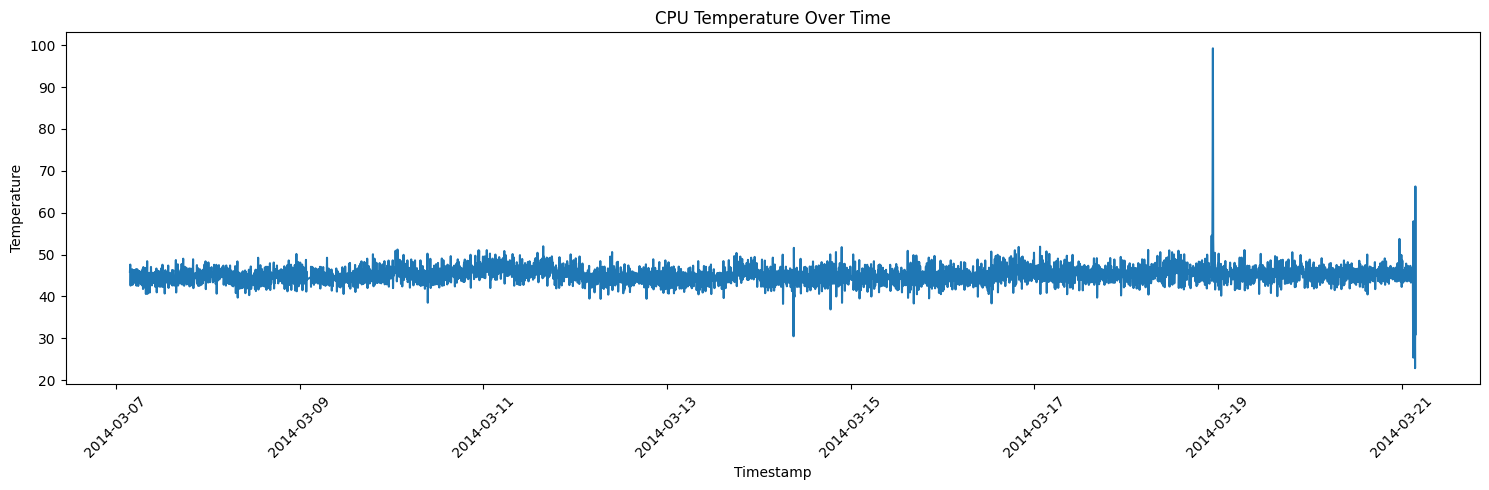

In [56]:
plt.figure(figsize=(15, 5))

plt.plot(lol["timestamp"], lol["value"])

plt.title("CPU Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [57]:
window_size = 288  # 24 hours of data if sampled every 5 minutes

lol["rolling_mean"] = lol["value"].rolling(window=window_size, min_periods=1).mean()
lol["rolling_std"] = lol["value"].rolling(window=window_size, min_periods=1).std()

# Calculate Z-Score (added 1e-5 to prevent division-by-zero on flatlines)
lol["z_score"] = (lol["value"] - lol["rolling_mean"]) / (lol["rolling_std"] + 1e-5)

# Step 4: Create the final anomaly flag (1 for anomaly, 0 for normal)
lol["is_anomaly"] = (lol["z_score"].abs() > 3.0).astype(int)

# Step 5: Check your results
print(lol[["timestamp", "value", "z_score", "is_anomaly"]].head())

            timestamp   value   z_score  is_anomaly
0 2014-03-07 03:41:00  45.868       NaN           0
1 2014-03-07 03:46:00  47.606  0.707101           0
2 2014-03-07 03:51:00  42.580 -1.085719           0
3 2014-03-07 03:56:00  46.030  0.241052           0
4 2014-03-07 04:01:00  44.992 -0.229511           0


In [58]:
# Counts consecutive anomalies. Resets to 0 when data goes back to normal.
lol['anomaly_duration_count'] = lol['is_anomaly'].groupby((lol['is_anomaly'] == 0).cumsum()).cumsum()


In [59]:
# Calculates the raw change from the previous data point
lol['temperature_velocity'] = lol['value'].diff().fillna(0)


In [60]:
# Percentage difference from the rolling mean
lol['pct_above_baseline'] = ((lol['value'] - lol['rolling_mean']) / (lol['rolling_mean'] + 1e-5)) * 100


In [61]:
lol.columns

Index(['timestamp', 'value', 'date', 'time', 'rolling_mean', 'rolling_std',
       'z_score', 'is_anomaly', 'anomaly_duration_count',
       'temperature_velocity', 'pct_above_baseline'],
      dtype='object')

# aws cloud watch

In [62]:
a=pd.read_csv(find_data("ec2_cpu_utilization_5f5533.csv"))

In [63]:
a.shape

(4032, 2)

In [64]:
a.head()

,timestamp,value
0,2014-02-14 14:27:00,51.846
1,2014-02-14 14:32:00,44.508
2,2014-02-14 14:37:00,41.244
3,2014-02-14 14:42:00,48.568
4,2014-02-14 14:47:00,46.714


In [65]:
# Function to get the Date (the first part of the split)
def get_date(text):
    return str(text).split()[0]

# Function to get the Time (the second part of the split)
def get_time(text):
    return str(text).split()[1]


In [66]:
a['date']=a['timestamp'].apply(get_date)
a['time']=a['timestamp'].apply(get_time)

In [67]:
a.columns

Index(['timestamp', 'value', 'date', 'time'], dtype='object')

In [68]:
a['timestamp'].isna().sum()

np.int64(0)

In [69]:
a['value'].isna().sum()

np.int64(0)

In [70]:
a['timestamp'].duplicated().sum()

np.int64(0)

In [71]:
a.describe()

,value
count,4032.000000
mean,43.110372
std,4.303565
min,34.766000
25%,39.296000
50%,42.918000
75%,46.006000
max,68.092000


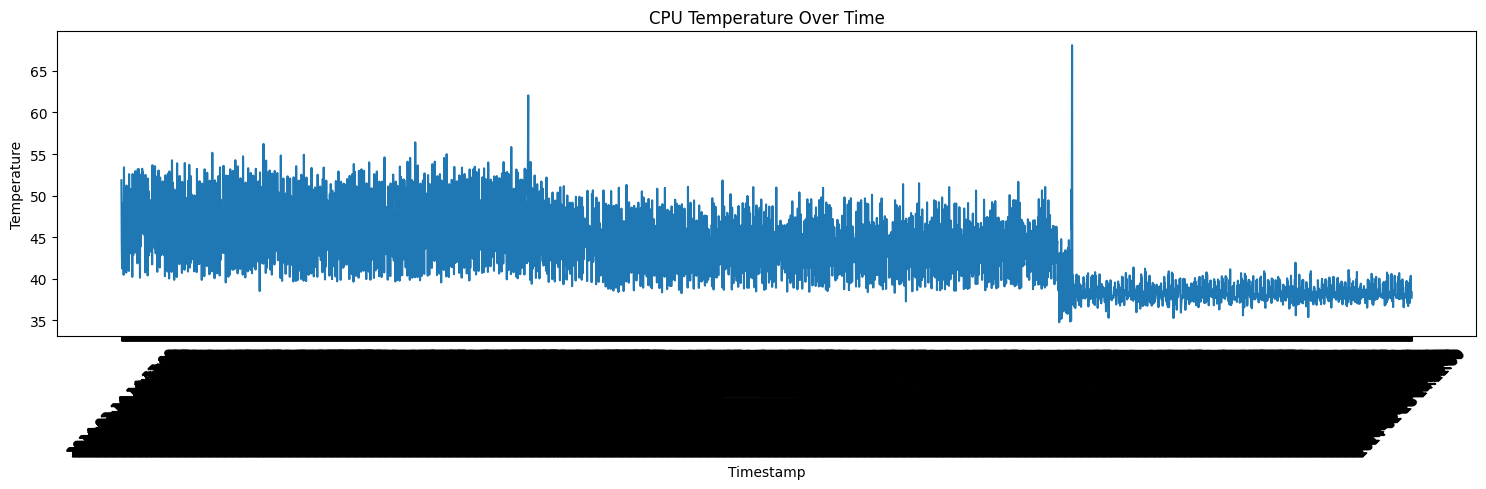

In [72]:
plt.figure(figsize=(15, 5))

plt.plot(a["timestamp"], a["value"])

plt.title("CPU Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [73]:
a.head()

,timestamp,value,date,time
0,2014-02-14 14:27:00,51.846,2014-02-14,14:27:00
1,2014-02-14 14:32:00,44.508,2014-02-14,14:32:00
2,2014-02-14 14:37:00,41.244,2014-02-14,14:37:00
3,2014-02-14 14:42:00,48.568,2014-02-14,14:42:00
4,2014-02-14 14:47:00,46.714,2014-02-14,14:47:00


In [74]:
a.sort_values(by='timestamp')
a['timestamp']=a['timestamp'].astype('datetime64[ns]')
a["timestamp"].diff().value_counts().head()

timestamp
0 days 00:05:00    4031
Name: count, dtype: int64

In [75]:
a['timestamp'].is_monotonic_increasing

True

In [76]:
window_size = 288  # 24 hours of data if sampled every 5 minutes

a["rolling_mean"] = a["value"].rolling(window=window_size, min_periods=1).mean()
a["rolling_std"] = a["value"].rolling(window=window_size, min_periods=1).std()

# Calculate Z-Score (added 1e-5 to prevent division-by-zero on flatlines)
a["z_score"] = (a["value"] - a["rolling_mean"]) / (a["rolling_std"] + 1e-5)

# Step 4: Create the final anomaly flag (1 for anomaly, 0 for normal)
a["is_anomaly"] = (a["z_score"].abs() > 3.0).astype(int)

# Step 5: Check your results
print(a[["timestamp", "value", "z_score", "is_anomaly"]].head())

            timestamp   value   z_score  is_anomaly
0 2014-02-14 14:27:00  51.846       NaN           0
1 2014-02-14 14:32:00  44.508 -0.707105           0
2 2014-02-14 14:37:00  41.244 -0.851212           0
3 2014-02-14 14:42:00  48.568  0.437238           0
4 2014-02-14 14:47:00  46.714  0.034375           0


In [77]:
# Counts consecutive anomalies. Resets to 0 when data goes back to normal.
a['anomaly_duration_count'] = a['is_anomaly'].groupby((a['is_anomaly'] == 0).cumsum()).cumsum()

# Calculates the raw change from the previous data point
a['temperature_velocity'] = a['value'].diff().fillna(0)

# Percentage difference from the rolling mean
a['pct_above_baseline'] = ((a['value'] - a['rolling_mean']) / (a['rolling_mean'] + 1e-5)) * 100


In [78]:
a['is_anomaly'].unique()

a['anomaly_duration_count'].unique()

array([0, 1])

In [79]:
b=pd.read_csv(find_data("ec2_disk_write_bytes_1ef3de.csv"))

In [80]:
b.shape

(4730, 2)

In [81]:
b.head()

,timestamp,value
0,2014-03-01 17:34:00,0.0
1,2014-03-01 17:39:00,0.0
2,2014-03-01 17:44:00,0.0
3,2014-03-01 17:49:00,0.0
4,2014-03-01 17:54:00,0.0


In [82]:
# Function to get the Date (the first part of the split)
def get_date(text):
    return str(text).split()[0]

# Function to get the Time (the second part of the split)
def get_time(text):
    return str(text).split()[1]


b['date']=b['timestamp'].apply(get_date)
b['time']=b['timestamp'].apply(get_time)

In [83]:
b['timestamp'].isna().sum()

np.int64(0)

In [84]:
b['value'].isna().sum()

np.int64(0)

In [85]:
b['timestamp'].duplicated().sum()

np.int64(11)

In [86]:
b.drop_duplicates(subset=['timestamp'],keep='first')

,timestamp,value,date,time
0,2014-03-01 17:34:00,0.0,2014-03-01,17:34:00
1,2014-03-01 17:39:00,0.0,2014-03-01,17:39:00
2,2014-03-01 17:44:00,0.0,2014-03-01,17:44:00
3,2014-03-01 17:49:00,0.0,2014-03-01,17:49:00
4,2014-03-01 17:54:00,0.0,2014-03-01,17:54:00
...,...,...,...,...
4725,2014-03-18 03:19:00,0.0,2014-03-18,03:19:00
4726,2014-03-18 03:24:00,0.0,2014-03-18,03:24:00
4727,2014-03-18 03:29:00,0.0,2014-03-18,03:29:00
4728,2014-03-18 03:34:00,0.0,2014-03-18,03:34:00


In [87]:
b['value'].value_counts()

value
0.0            4249
9011.2            7
24576.0           5
20480.0           4
25395.2           3
               ... 
143207000.0       1
30673300.0        1
1707210.0         1
42272400.0        1
171071000.0       1
Name: count, Length: 448, dtype: int64

In [88]:
b.sort_values(by='timestamp')
b['timestamp']=b['timestamp'].astype('datetime64[ns]')
b["timestamp"].diff().value_counts().head()

timestamp
0 days 00:05:00    4716
0 days 00:00:00      11
0 days 01:01:00       1
0 days 00:04:00       1
Name: count, dtype: int64

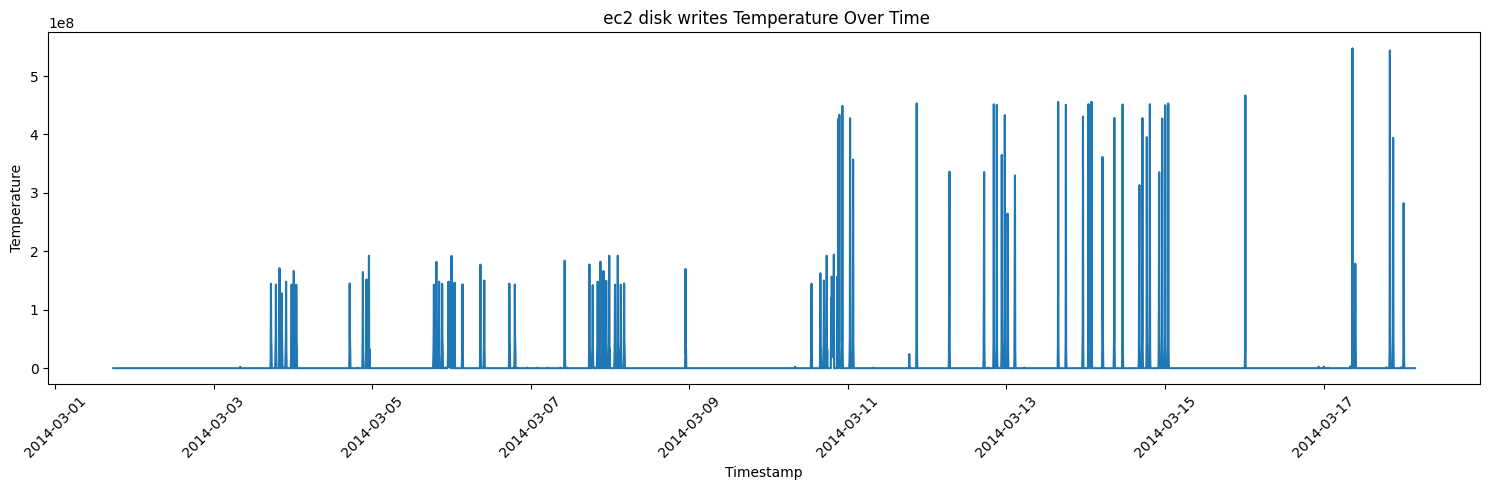

In [89]:
plt.figure(figsize=(15, 5))

plt.plot(b["timestamp"], b["value"])

plt.title(" ec2 disk writes Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [90]:
window_size = 288  # 24 hours of data if sampled every 5 minutes

b["rolling_mean"] = b["value"].rolling(window=window_size, min_periods=1).mean()
b["rolling_std"] = b["value"].rolling(window=window_size, min_periods=1).std()

# Calculate Z-Score (added 1e-5 to prevent division-by-zero on flatlines)
b["z_score"] = (b["value"] - b["rolling_mean"]) / (b["rolling_std"] + 1e-5)

# Step 4: Create the final anomaly flag (1 for anomaly, 0 for normal)
b["is_anomaly"] = (b["z_score"].abs() > 3.0).astype(int)

# Step 5: Check your results
print(b[["timestamp", "value", "z_score", "is_anomaly"]].head())

            timestamp  value  z_score  is_anomaly
0 2014-03-01 17:34:00    0.0      NaN           0
1 2014-03-01 17:39:00    0.0      0.0           0
2 2014-03-01 17:44:00    0.0      0.0           0
3 2014-03-01 17:49:00    0.0      0.0           0
4 2014-03-01 17:54:00    0.0      0.0           0


In [91]:
# Counts consecutive anomalies. Resets to 0 when data goes back to normal.
b['anomaly_duration_count'] = b['is_anomaly'].groupby((b['is_anomaly'] == 0).cumsum()).cumsum()

# Calculates the raw change from the previous data point
b['temperature_velocity'] = b['value'].diff().fillna(0)

# Percentage difference from the rolling mean
b['pct_above_baseline'] = ((b['value'] - b['rolling_mean']) / (b['rolling_mean'] + 1e-5)) * 100


In [92]:
# Replace any starting NaN values with 0 so the dataset is perfectly clean
b = b.fillna(0)


In [93]:
b.isna().sum()

timestamp                 0
value                     0
date                      0
time                      0
rolling_mean              0
rolling_std               0
z_score                   0
is_anomaly                0
anomaly_duration_count    0
temperature_velocity      0
pct_above_baseline        0
dtype: int64

In [94]:
b.head(1)

,timestamp,value,date,time,rolling_mean,rolling_std,z_score,is_anomaly,anomaly_duration_count,temperature_velocity,pct_above_baseline
0,2014-03-01 17:34:00,0.0,2014-03-01,17:34:00,0.0,0.0,0.0,0,0,0.0,0.0


In [95]:
c=pd.read_csv(find_data("ec2_network_in_5abac7.csv"))

In [96]:
c.shape

(4730, 2)

In [97]:
c.head()

,timestamp,value
0,2014-03-01 17:36:00,42.0
1,2014-03-01 17:41:00,94.8
2,2014-03-01 17:46:00,42.0
3,2014-03-01 17:51:00,68.4
4,2014-03-01 17:56:00,68.4


In [98]:
# Function to get the Date (the first part of the split)
def get_date(text):
    return str(text).split()[0]

# Function to get the Time (the second part of the split)
def get_time(text):
    return str(text).split()[1]


c['date']=c['timestamp'].apply(get_date)
c['time']=c['timestamp'].apply(get_time)

In [99]:
c.value_counts()

timestamp            value  date        time    
2014-03-09 03:00:00  42.0   2014-03-09  03:00:00    5
                     60.0   2014-03-09  03:00:00    2
                     68.4   2014-03-09  03:00:00    2
2014-03-18 02:26:00  108.0  2014-03-18  02:26:00    1
2014-03-18 02:21:00  42.0   2014-03-18  02:21:00    1
                                                   ..
2014-03-18 03:21:00  42.0   2014-03-18  03:21:00    1
2014-03-18 03:26:00  42.0   2014-03-18  03:26:00    1
2014-03-18 03:31:00  118.5  2014-03-18  03:31:00    1
2014-03-18 03:36:00  75.0   2014-03-18  03:36:00    1
2014-03-01 19:11:00  42.0   2014-03-01  19:11:00    1
Name: count, Length: 4724, dtype: int64

In [100]:
c['timestamp'].isna().sum()

np.int64(0)

In [101]:
c['timestamp'].duplicated().sum()

np.int64(11)

In [102]:
c=c.drop_duplicates(subset='timestamp',keep='first')

In [103]:
c['value'].isna().sum()

np.int64(0)

In [104]:
c.sort_values(by='timestamp')
c['timestamp']=c['timestamp'].astype('datetime64[ns]')
c["timestamp"].diff().value_counts().head()

timestamp
0 days 00:05:00    4716
0 days 01:04:00       1
0 days 00:01:00       1
Name: count, dtype: int64

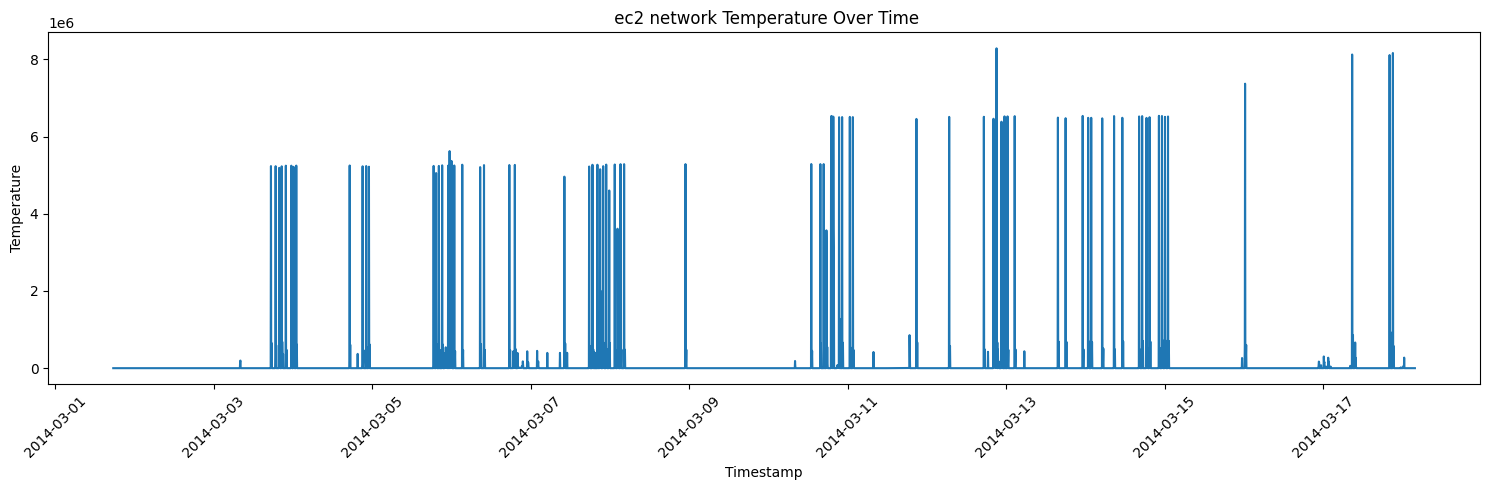

In [105]:
plt.figure(figsize=(15, 5))

plt.plot(c["timestamp"], c["value"])

plt.title(" ec2 network Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [106]:
window_size = 288  # 24 hours of data if sampled every 5 minutes

c["rolling_mean"] = c["value"].rolling(window=window_size, min_periods=1).mean()
c["rolling_std"] = c["value"].rolling(window=window_size, min_periods=1).std()

# Calculate Z-Score (added 1e-5 to prevent division-by-zero on flatlines)
c["z_score"] = (c["value"] - c["rolling_mean"]) / (c["rolling_std"] + 1e-5)

# Step 4: Create the final anomaly flag (1 for anomaly, 0 for normal)
c["is_anomaly"] = (c["z_score"].abs() > 3.0).astype(int)

# Step 5: Check your results
print(c[["timestamp", "value", "z_score", "is_anomaly"]].head())

            timestamp  value   z_score  is_anomaly
0 2014-03-01 17:36:00   42.0       NaN           0
1 2014-03-01 17:41:00   94.8  0.707107           0
2 2014-03-01 17:46:00   42.0 -0.577350           0
3 2014-03-01 17:51:00   68.4  0.261116           0
4 2014-03-01 17:56:00   68.4  0.239046           0


In [107]:
# Counts consecutive anomalies. Resets to 0 when data goes back to normal.
c['anomaly_duration_count'] = c['is_anomaly'].groupby((c['is_anomaly'] == 0).cumsum()).cumsum()

# Calculates the raw change from the previous data point
c['temperature_velocity'] = c['value'].diff().fillna(0)

# Percentage difference from the rolling mean
c['pct_above_baseline'] = ((c['value'] - c['rolling_mean']) / (c['rolling_mean'] + 1e-5)) * 100

In [108]:
c=c.fillna(0)

In [109]:
c.isna().sum()

timestamp                 0
value                     0
date                      0
time                      0
rolling_mean              0
rolling_std               0
z_score                   0
is_anomaly                0
anomaly_duration_count    0
temperature_velocity      0
pct_above_baseline        0
dtype: int64

artifical anamoly

In [110]:
d=pd.read_csv(find_data("art_daily_jumpsup.csv"))

In [111]:
d.shape

(4032, 2)

In [112]:
d.head()

,timestamp,value
0,2014-04-01 00:00:00,19.761252
1,2014-04-01 00:05:00,20.500833
2,2014-04-01 00:10:00,19.961641
3,2014-04-01 00:15:00,21.490266
4,2014-04-01 00:20:00,20.187739


In [113]:
def get_date(text):
    return str(text).split()[0]

# Function to get the Time (the second part of the split)
def get_time(text):
    return str(text).split()[1]


d['date']=d['timestamp'].apply(get_date)
d['time']=d['timestamp'].apply(get_time)

In [114]:
d.columns

Index(['timestamp', 'value', 'date', 'time'], dtype='object')

In [115]:
d['timestamp'].isna().sum()

np.int64(0)

In [116]:
d['value'].isna().sum()

np.int64(0)

In [117]:
d['timestamp'].duplicated().sum()

np.int64(0)

In [118]:
d.sort_values(by='timestamp')
d['timestamp']=d['timestamp'].astype('datetime64[ns]')
d["timestamp"].diff().value_counts().head()

timestamp
0 days 00:05:00    4031
Name: count, dtype: int64

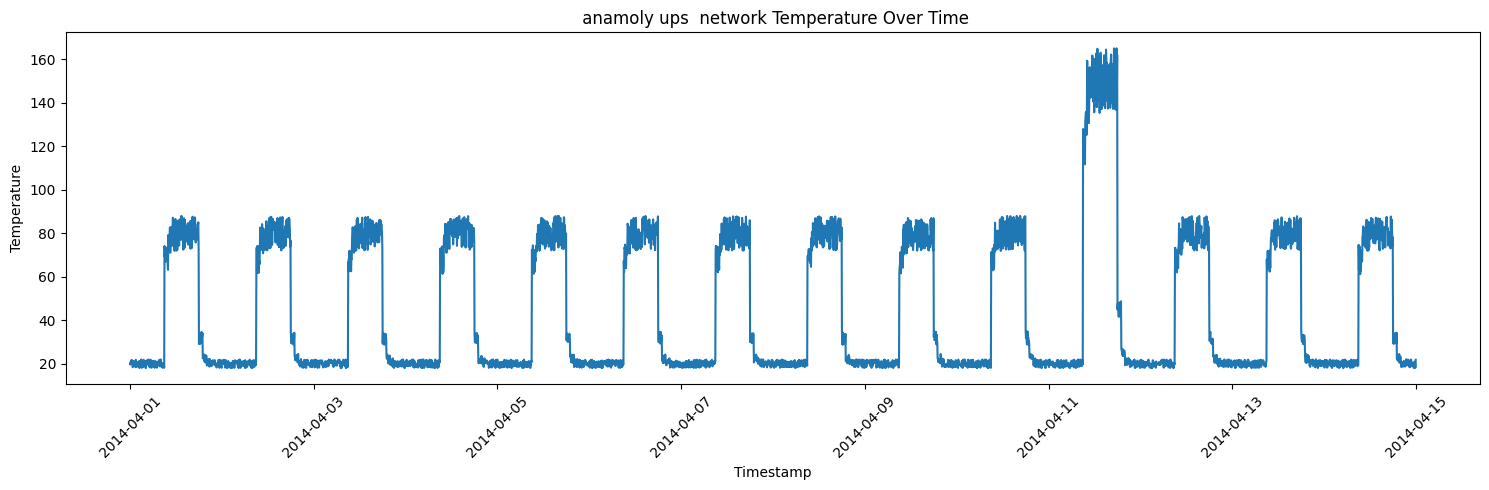

In [119]:
plt.figure(figsize=(15, 5))

plt.plot(d["timestamp"], d["value"])

plt.title(" anamoly ups  network Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [120]:
window_size = 288  # 24 hours of data if sampled every 5 minutes

d["rolling_mean"] = d["value"].rolling(window=window_size, min_periods=1).mean()
d["rolling_std"] = d["value"].rolling(window=window_size, min_periods=1).std()

# Calculate Z-Score (added 1e-5 to prevent division-by-zero on flatlines)
d["z_score"] = (d["value"] - d["rolling_mean"]) / (d["rolling_std"] + 1e-5)

# Step 4: Create the final anomaly flag (1 for anomaly, 0 for normal)
d["is_anomaly"] = (d["z_score"].abs() > 3.0).astype(int)

# Step 5: Check your results
print(d[["timestamp", "value", "z_score", "is_anomaly"]].head())

            timestamp      value   z_score  is_anomaly
0 2014-04-01 00:00:00  19.761252       NaN           0
1 2014-04-01 00:05:00  20.500833  0.707093           0
2 2014-04-01 00:10:00  19.961641 -0.295240           0
3 2014-04-01 00:15:00  21.490266  1.372337           0
4 2014-04-01 00:20:00  20.187739 -0.283815           0


In [121]:
# Counts consecutive anomalies. Resets to 0 when data goes back to normal.
d['anomaly_duration_count'] = d['is_anomaly'].groupby((d['is_anomaly'] == 0).cumsum()).cumsum()

# Calculates the raw change from the previous data point
d['temperature_velocity'] = d['value'].diff().fillna(0)

# Percentage difference from the rolling mean
d['pct_above_baseline'] = ((d['value'] - d['rolling_mean']) / (d['rolling_mean'] + 1e-5)) * 100


In [122]:
d.isna().sum()

timestamp                 0
value                     0
date                      0
time                      0
rolling_mean              0
rolling_std               1
z_score                   1
is_anomaly                0
anomaly_duration_count    0
temperature_velocity      0
pct_above_baseline        0
dtype: int64

In [123]:
d=d.fillna(0)

In [124]:
e=pd.read_csv(find_data("art_daily_jumpsdown.csv"))

In [125]:
e.shape

(4032, 2)

In [126]:
e.head()

,timestamp,value
0,2014-04-01 00:00:00,18.090486
1,2014-04-01 00:05:00,20.359843
2,2014-04-01 00:10:00,21.105470
3,2014-04-01 00:15:00,21.151585
4,2014-04-01 00:20:00,18.137141


In [127]:
# Function to get the Date (the first part of the split)
def get_date(text):
    return str(text).split()[0]

# Function to get the Time (the second part of the split)
def get_time(text):
    return str(text).split()[1]


e['date']=e['timestamp'].apply(get_date)
e['time']=e['timestamp'].apply(get_time)

In [128]:
e.columns

Index(['timestamp', 'value', 'date', 'time'], dtype='object')

In [129]:
e['timestamp'].isna().sum()

np.int64(0)

In [130]:
e['timestamp'].duplicated().sum()

np.int64(0)

In [131]:
e['value'].isna().sum()

np.int64(0)

In [132]:
e.sort_values(by='timestamp')
e['timestamp']=e['timestamp'].astype('datetime64[ns]')
e["timestamp"].diff().value_counts().head()

timestamp
0 days 00:05:00    4031
Name: count, dtype: int64

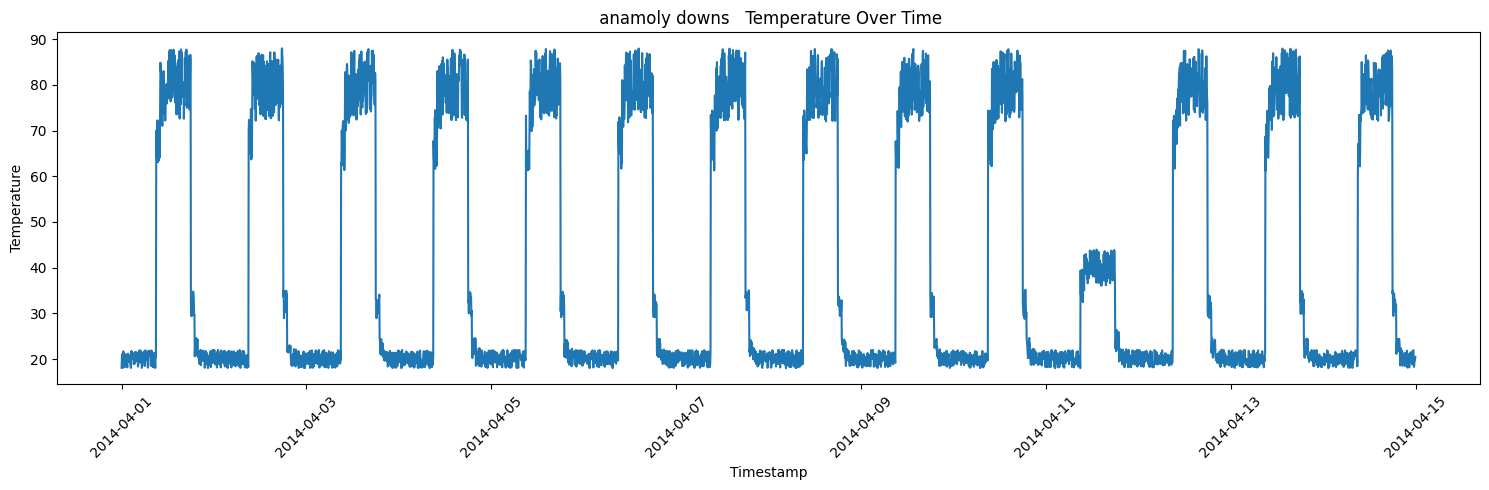

In [133]:
plt.figure(figsize=(15, 5))

plt.plot(e["timestamp"], e["value"])

plt.title(" anamoly downs   Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [134]:
window_size = 288  # 24 hours of data if sampled every 5 minutes

e["rolling_mean"] = e["value"].rolling(window=window_size, min_periods=1).mean()
e["rolling_std"] = e["value"].rolling(window=window_size, min_periods=1).std()

# Calculate Z-Score (added 1e-5 to prevent division-by-zero on flatlines)
e["z_score"] = (e["value"] - e["rolling_mean"]) / (e["rolling_std"] + 1e-5)

# Step 4: Create the final anomaly flag (1 for anomaly, 0 for normal)
e["is_anomaly"] = (e["z_score"].abs() > 3.0).astype(int)

# Step 5: Check your results
print(e[["timestamp", "value", "z_score", "is_anomaly"]].head())

            timestamp      value   z_score  is_anomaly
0 2014-04-01 00:00:00  18.090486       NaN           0
1 2014-04-01 00:05:00  20.359843  0.707102           0
2 2014-04-01 00:10:00  21.105470  0.798246           0
3 2014-04-01 00:15:00  21.151585  0.678095           0
4 2014-04-01 00:20:00  18.137141 -1.057311           0


In [135]:
# Counts consecutive anomalies. Resets to 0 when data goes back to normal.
e['anomaly_duration_count'] = e['is_anomaly'].groupby((e['is_anomaly'] == 0).cumsum()).cumsum()

# Calculates the raw change from the previous data point
e['temperature_velocity'] = e['value'].diff().fillna(0)

# Percentage difference from the rolling mean
e['pct_above_baseline'] = ((e['value'] - e['rolling_mean']) / (e['rolling_mean'] + 1e-5)) * 100

In [136]:
e.isna().sum()

timestamp                 0
value                     0
date                      0
time                      0
rolling_mean              0
rolling_std               1
z_score                   1
is_anomaly                0
anomaly_duration_count    0
temperature_velocity      0
pct_above_baseline        0
dtype: int64

In [137]:
e=e.fillna(0)

In [138]:
e.isna().sum()

timestamp                 0
value                     0
date                      0
time                      0
rolling_mean              0
rolling_std               0
z_score                   0
is_anomaly                0
anomaly_duration_count    0
temperature_velocity      0
pct_above_baseline        0
dtype: int64

# **no anamoly**

In [139]:
f=pd.read_csv(find_data("art_daily_small_noise.csv"))

In [140]:
f.shape

(4032, 2)

In [141]:
f.head()

,timestamp,value
0,2014-04-01 00:00:00,18.324919
1,2014-04-01 00:05:00,21.970327
2,2014-04-01 00:10:00,18.624806
3,2014-04-01 00:15:00,21.953684
4,2014-04-01 00:20:00,21.909120


In [142]:
# Function to get the Date (the first part of the split)
def get_date(text):
    return str(text).split()[0]

# Function to get the Time (the second part of the split)
def get_time(text):
    return str(text).split()[1]


f['date']=f['timestamp'].apply(get_date)
f['time']=f['timestamp'].apply(get_time)

In [143]:
f.columns

Index(['timestamp', 'value', 'date', 'time'], dtype='object')

In [144]:
f['timestamp'].isna().sum()

np.int64(0)

In [145]:
f['timestamp'].duplicated().sum()

np.int64(0)

In [146]:
f['value'].isna().sum()

np.int64(0)

In [147]:
f.sort_values(by='timestamp')
f['timestamp']=f['timestamp'].astype('datetime64[ns]')
f["timestamp"].diff().value_counts().head()

timestamp
0 days 00:05:00    4031
Name: count, dtype: int64

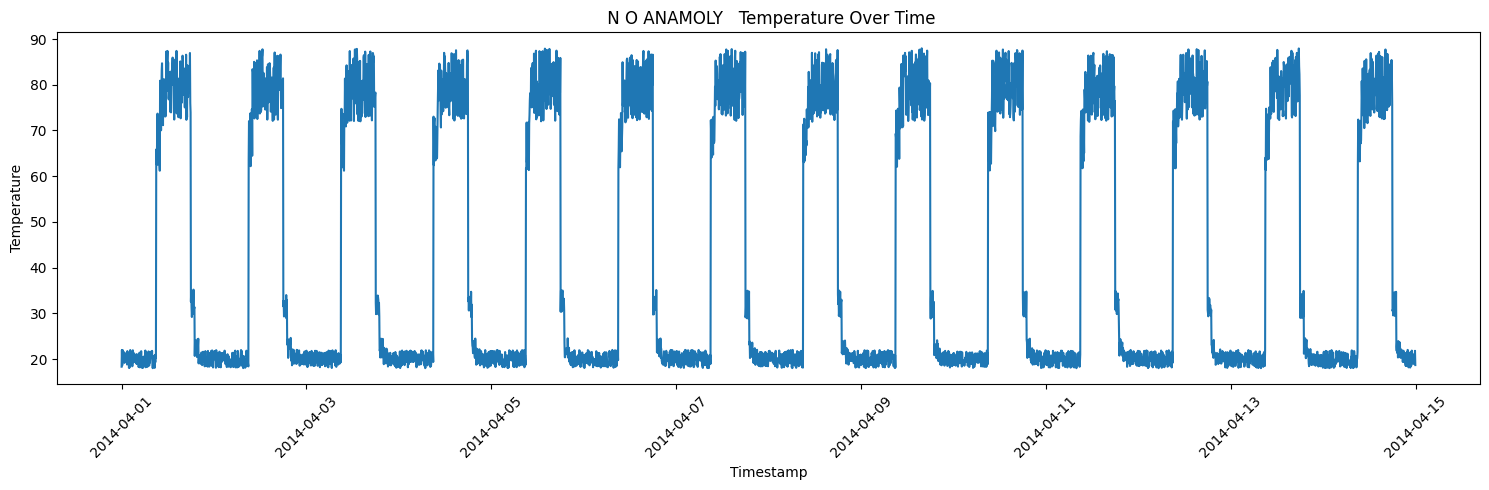

In [148]:
plt.figure(figsize=(15, 5))

plt.plot(f["timestamp"], f["value"])

plt.title(" N O ANAMOLY   Temperature Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [149]:
window_size = 288  # 24 hours of data if sampled every 5 minutes

f["rolling_mean"] = f["value"].rolling(window=window_size, min_periods=1).mean()
f["rolling_std"] = f["value"].rolling(window=window_size, min_periods=1).std()

# Calculate Z-Score (added 1e-5 to prevent division-by-zero on flatlines)
f["z_score"] = (f["value"] - f["rolling_mean"]) / (f["rolling_std"] + 1e-5)

# Step 4: Create the final anomaly flag (1 for anomaly, 0 for normal)
f["is_anomaly"] = (f["z_score"].abs() > 3.0).astype(int)

# Step 5: Check your results
print(f[["timestamp", "value", "z_score", "is_anomaly"]].head())

            timestamp      value   z_score  is_anomaly
0 2014-04-01 00:00:00  18.324919       NaN           0
1 2014-04-01 00:05:00  21.970327  0.707104           0
2 2014-04-01 00:10:00  18.624806 -0.501666           0
3 2014-04-01 00:15:00  21.953684  0.860294           0
4 2014-04-01 00:20:00  21.909120  0.710585           0


In [150]:
# Counts consecutive anomalies. Resets to 0 when data goes back to normal.
f['anomaly_duration_count'] = f['is_anomaly'].groupby((f['is_anomaly'] == 0).cumsum()).cumsum()

# Calculates the raw change from the previous data point
f['temperature_velocity'] = f['value'].diff().fillna(0)

# Percentage difference from the rolling mean
f['pct_above_baseline'] = ((f['value'] - f['rolling_mean']) / (f['rolling_mean'] + 1e-5)) * 100

In [151]:
f.isna().sum()

timestamp                 0
value                     0
date                      0
time                      0
rolling_mean              0
rolling_std               1
z_score                   1
is_anomaly                0
anomaly_duration_count    0
temperature_velocity      0
pct_above_baseline        0
dtype: int64

In [152]:
f=f.fillna(0)

In [153]:
f.isna().sum()

timestamp                 0
value                     0
date                      0
time                      0
rolling_mean              0
rolling_std               0
z_score                   0
is_anomaly                0
anomaly_duration_count    0
temperature_velocity      0
pct_above_baseline        0
dtype: int64

# **Labels folder**

In [154]:
import json

with open(find_label("combined_windows.json")) as f:
    windows = json.load(f)

print(len(windows))   # should be 58
print(windows["realAWSCloudwatch/rds_cpu_utilization_e47b3b.csv"])

58
[['2014-04-12 22:32:00.000000', '2014-04-13 15:12:00.000000'], ['2014-04-18 15:07:00.000000', '2014-04-19 07:47:00.000000']]


In [155]:
import pandas as pd

rows = [{"file": k, "start": s, "end": e}
        for k, v in windows.items() for s, e in v]
windows_df = pd.DataFrame(rows)
windows_df.head()

,file,start,end
0,artificialWithAnomaly/art_daily_flatmiddle.csv,2014-04-10 07:15:00.000000,2014-04-11 16:45:00.000000
1,artificialWithAnomaly/art_daily_jumpsdown.csv,2014-04-10 16:15:00.000000,2014-04-12 01:45:00.000000
2,artificialWithAnomaly/art_daily_jumpsup.csv,2014-04-10 16:15:00.000000,2014-04-12 01:45:00.000000
3,artificialWithAnomaly/art_daily_nojump.csv,2014-04-10 16:15:00.000000,2014-04-12 01:45:00.000000
4,artificialWithAnomaly/art_increase_spike_densi...,2014-04-07 06:25:00.000000,2014-04-08 15:55:00.000000


In [156]:
my_files = [
    "artificialWithAnomaly/art_daily_jumpsdown.csv",
    "artificialWithAnomaly/art_daily_jumpsup.csv",
    "artificialNoAnomaly/art_daily_small_noise.csv",
    "realKnownCause/machine_temperature_system_failure.csv",
    "realKnownCause/cpu_utilization_asg_misconfiguration.csv",
    "realKnownCause/ec2_request_latency_system_failure.csv",
    "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv",
    "realAWSCloudwatch/ec2_disk_write_bytes_1ef3de.csv",
    "realAWSCloudwatch/ec2_network_in_5abac7.csv",
]

my_windows = windows_df[windows_df["file"].isin(my_files)]
my_windows["file"].value_counts()

file
realKnownCause/machine_temperature_system_failure.csv      4
realKnownCause/ec2_request_latency_system_failure.csv      3
realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv           2
realAWSCloudwatch/ec2_network_in_5abac7.csv                2
realAWSCloudwatch/ec2_disk_write_bytes_1ef3de.csv          1
artificialWithAnomaly/art_daily_jumpsup.csv                1
artificialWithAnomaly/art_daily_jumpsdown.csv              1
realKnownCause/cpu_utilization_asg_misconfiguration.csv    1
Name: count, dtype: int64

In [157]:
import pandas as pd
import os

data = {}      # keeps each file's table, so we can reuse it later
summary = []

for key in my_files:
    name = os.path.basename(key)   # just the file name
    df = pd.read_csv(find_data(name), parse_dates=["timestamp"])

    df["in_window"] = False
    for start, end in windows[key]:
        df.loc[df["timestamp"].between(pd.Timestamp(start), pd.Timestamp(end)), "in_window"] = True

    data[name] = df
    summary.append({
        "file": name,
        "rows": len(df),
        "first_time": df["timestamp"].min(),
        "last_time": df["timestamp"].max(),
        "windows": len(windows[key]),
        "rows_in_window": df["in_window"].sum(),
        "pct_in_window": round(df["in_window"].mean() * 100, 1),
    })

pd.DataFrame(summary)

,file,rows,first_time,last_time,windows,rows_in_window,pct_in_window
0,art_daily_jumpsdown.csv,4032,2014-04-01 00:00:00,2014-04-14 23:55:00,1,403,10.0
1,art_daily_jumpsup.csv,4032,2014-04-01 00:00:00,2014-04-14 23:55:00,1,403,10.0
2,art_daily_small_noise.csv,4032,2014-04-01 00:00:00,2014-04-14 23:55:00,0,0,0.0
3,machine_temperature_system_failure.csv,22695,2013-12-02 21:15:00,2014-02-19 15:25:00,4,2268,10.0
4,cpu_utilization_asg_misconfiguration.csv,18050,2014-05-14 01:14:00,2014-07-15 17:19:00,1,1499,8.3
5,ec2_request_latency_system_failure.csv,4032,2014-03-07 03:41:00,2014-03-21 03:41:00,3,346,8.6
6,ec2_cpu_utilization_5f5533.csv,4032,2014-02-14 14:27:00,2014-02-28 14:22:00,2,402,10.0
7,ec2_disk_write_bytes_1ef3de.csv,4730,2014-03-01 17:34:00,2014-03-18 03:39:00,1,473,10.0
8,ec2_network_in_5abac7.csv,4730,2014-03-01 17:36:00,2014-03-18 03:41:00,2,474,10.0


# **charts**

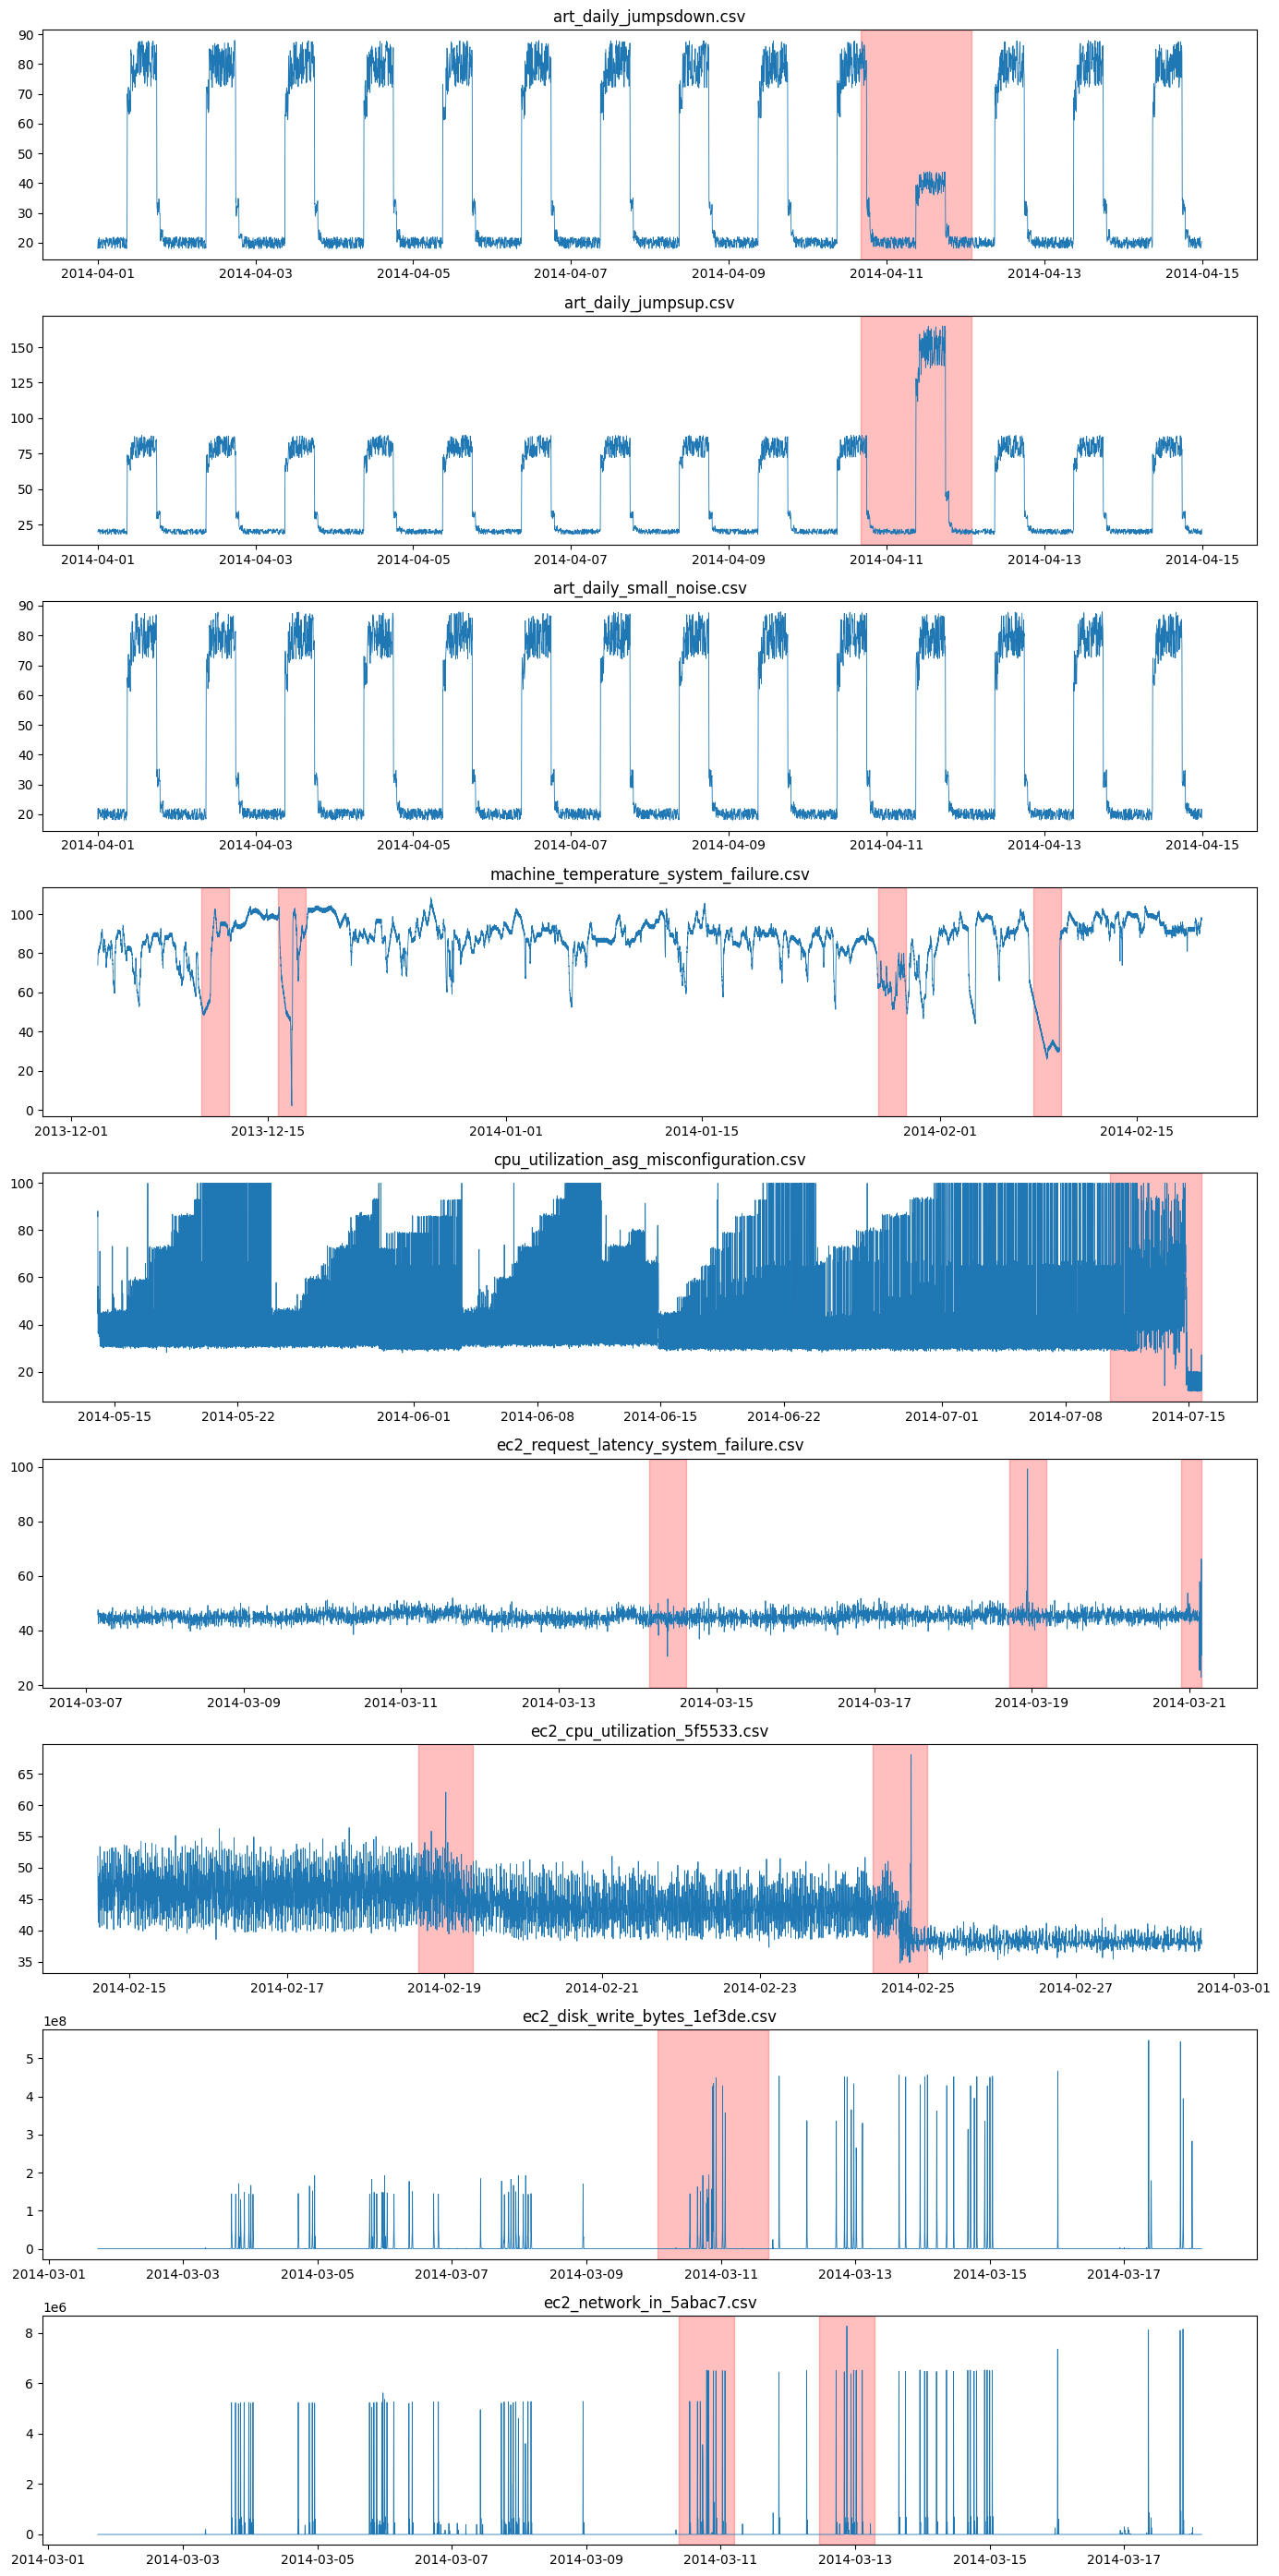

In [158]:

import matplotlib.pyplot as plt

windows_by_name = {os.path.basename(k): windows[k] for k in my_files}

fig, axes = plt.subplots(9, 1, figsize=(14, 28))

for ax, (name, df) in zip(axes, data.items()):
    ax.plot(df["timestamp"], df["value"], linewidth=0.6)
    for start, end in windows_by_name[name]:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="red", alpha=0.25)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [159]:
rows = []
for name, df in data.items():
    inside  = df[df["in_window"]]["value"]
    outside = df[~df["in_window"]]["value"]
    mu, sd = outside.mean(), outside.std()

    rows.append({
        "file": name,
        "mean_outside": round(mu, 2),
        "mean_inside": round(inside.mean(), 2) if len(inside) else None,
        "biggest_jump_outside": round(((outside - mu).abs() / sd).max(), 1),
        "biggest_jump_inside": round(((inside - mu).abs() / sd).max(), 1) if len(inside) else None,
    })

pd.DataFrame(rows)

,file,mean_outside,mean_inside,biggest_jump_outside,biggest_jump_inside
0,art_daily_jumpsdown.csv,42.89,29.08,1.6,1.6
1,art_daily_jumpsup.csv,42.92,58.65,1.6,4.3
2,art_daily_small_noise.csv,42.44,NaN,1.6,NaN
3,machine_temperature_system_failure.csv,88.36,64.02,4.5,8.8
4,cpu_utilization_asg_misconfiguration.csv,37.64,45.38,4.2,4.2
5,ec2_request_latency_system_failure.csv,45.16,45.15,4.3,28.2
6,ec2_cpu_utilization_5f5533.csv,43.05,43.69,3.1,5.9
7,ec2_disk_write_bytes_1ef3de.csv,6127133.17,10671409.14,13.8,11.3
8,ec2_network_in_5abac7.csv,96701.89,316365.00,11.7,11.8


In [160]:
print(type(windows), len(windows))
print(list(windows)[:3])
print(windows["realKnownCause/machine_temperature_system_failure.csv"])
print(all(k in windows for k in my_files))   # should print True

<class 'dict'> 58
['artificialNoAnomaly/art_daily_no_noise.csv', 'artificialNoAnomaly/art_daily_perfect_square_wave.csv', 'artificialNoAnomaly/art_daily_small_noise.csv']
[['2013-12-10 06:25:00.000000', '2013-12-12 05:35:00.000000'], ['2013-12-15 17:50:00.000000', '2013-12-17 17:00:00.000000'], ['2014-01-27 14:20:00.000000', '2014-01-29 13:30:00.000000'], ['2014-02-07 14:55:00.000000', '2014-02-09 14:05:00.000000']]
True


labels

In [161]:
import json

with open(find_label("combined_labels.json")) as f:
    windows = json.load(f)

print(len(windows))   # should be 58
print(windows["realAWSCloudwatch/rds_cpu_utilization_e47b3b.csv"])

58
['2014-04-13 06:52:00', '2014-04-18 23:27:00']


In [162]:
import json, os

with open(find_label("combined_labels.json")) as f:
    labels = json.load(f)

# --- Structure ---
print(type(labels), len(labels))     # expect dict, 58
print(list(labels.keys())[:5])       # sample keys

# --- Match your local CSVs to JSON keys (by file name, since keys have folder prefixes) ---
local_csvs = sorted(NINE_CSVS)
by_name = {k.split("/")[-1]: k for k in labels}

print(f"\n{len(local_csvs)} local CSVs")
for name in local_csvs:
    key = by_name.get(name)
    n = len(labels[key]) if key else "NOT FOUND"
    print(f"{name:55s} -> {key}  | anomalies: {n}")

# --- One entry in detail ---
key = by_name["ec2_cpu_utilization_5f5533.csv"]
print("\nKEY:", key)
print(type(labels[key]), len(labels[key]))
print(labels[key])

<class 'dict'> 58
['artificialNoAnomaly/art_daily_no_noise.csv', 'artificialNoAnomaly/art_daily_perfect_square_wave.csv', 'artificialNoAnomaly/art_daily_small_noise.csv', 'artificialNoAnomaly/art_flatline.csv', 'artificialNoAnomaly/art_noisy.csv']

9 local CSVs
art_daily_jumpsdown.csv                                 -> artificialWithAnomaly/art_daily_jumpsdown.csv  | anomalies: 1
art_daily_jumpsup.csv                                   -> artificialWithAnomaly/art_daily_jumpsup.csv  | anomalies: 1
art_daily_small_noise.csv                               -> artificialNoAnomaly/art_daily_small_noise.csv  | anomalies: 0
cpu_utilization_asg_misconfiguration.csv                -> realKnownCause/cpu_utilization_asg_misconfiguration.csv  | anomalies: 2
ec2_cpu_utilization_5f5533.csv                          -> realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv  | anomalies: 2
ec2_disk_write_bytes_1ef3de.csv                         -> realAWSCloudwatch/ec2_disk_write_bytes_1ef3de.csv  | anomalies:

In [163]:
import json
import pandas as pd

with open(find_label("combined_windows.json")) as f:
    windows_json = json.load(f)

# Reuses `labels` and `by_name` from the previous cell
rows = []
for name, key in sorted(by_name.items()):
    if not (name in NINE_CSVS):
        continue  # only your nine files

    lab = pd.to_datetime(labels[key])
    win = [(pd.to_datetime(s), pd.to_datetime(e)) for s, e in windows_json.get(key, [])]

    # Does each label fall inside at least one window?
    covered = sum(any(s <= t <= e for s, e in win) for t in lab)

    # Position of each label inside its window (0 = start, 0.5 = center, 1 = end)
    positions = []
    for t in lab:
        for s, e in win:
            if s <= t <= e:
                positions.append(round((t - s) / (e - s), 2))
                break

    rows.append({
        "file": name,
        "n_labels": len(lab),
        "n_windows": len(win),
        "counts_match": len(lab) == len(win),
        "labels_in_window": f"{covered}/{len(lab)}",
        "window_length": str(win[0][1] - win[0][0]) if win else "-",
        "label_position": positions,
    })

report = pd.DataFrame(rows)
print(report.to_string(index=False))

                                    file  n_labels  n_windows  counts_match labels_in_window   window_length       label_position
                 art_daily_jumpsdown.csv         1          1          True              1/1 1 days 09:30:00                [0.5]
                   art_daily_jumpsup.csv         1          1          True              1/1 1 days 09:30:00                [0.5]
               art_daily_small_noise.csv         0          0          True              0/0               -                   []
cpu_utilization_asg_misconfiguration.csv         2          1         False              2/2 5 days 04:50:00          [0.3, 0.84]
          ec2_cpu_utilization_5f5533.csv         2          2          True              2/2 0 days 16:40:00           [0.5, 0.5]
         ec2_disk_write_bytes_1ef3de.csv         1          1          True              1/1 1 days 15:20:00                [0.5]
               ec2_network_in_5abac7.csv         2          2          True              2

In [164]:
key = by_name["ec2_request_latency_system_failure.csv"]
for w in windows_json[key]:
    print(w)
print(labels[key])

['2014-03-14 03:31:00.000000', '2014-03-14 14:41:00.000000']
['2014-03-18 17:06:00.000000', '2014-03-19 04:16:00.000000']
['2014-03-20 21:26:00.000000', '2014-03-21 03:41:00.000000']
['2014-03-14 09:06:00', '2014-03-18 22:41:00', '2014-03-21 03:01:00']


combined windows label

In [165]:
import json, os
import pandas as pd

with open(find_label("combined_windows_tiny.json")) as f:
    tiny = json.load(f)
with open(find_label("combined_windows.json")) as f:
    windows_json = json.load(f)
with open(find_label("combined_labels.json")) as f:
    labels = json.load(f)

print(type(tiny), len(tiny))
print(list(tiny.keys())[:5])
print("same keys as combined_windows:", set(tiny) == set(windows_json))
print("only in tiny   :", sorted(set(tiny) - set(windows_json))[:5])
print("only in regular:", len(set(windows_json) - set(tiny)))

# Match your nine local CSVs by file name, without crashing on missing ones
local_csvs = sorted(NINE_CSVS)
by_name = {k.split("/")[-1]: k for k in tiny}

for name in local_csvs:
    print(f"{name:45s} in tiny: {name in by_name}")

<class 'dict'> 2
['realKnownCause/nyc_taxi.csv', 'realKnownCause/rogue_agent_key_hold.csv']
same keys as combined_windows: False
only in tiny   : []
only in regular: 56
art_daily_jumpsdown.csv                       in tiny: False
art_daily_jumpsup.csv                         in tiny: False
art_daily_small_noise.csv                     in tiny: False
cpu_utilization_asg_misconfiguration.csv      in tiny: False
ec2_cpu_utilization_5f5533.csv                in tiny: False
ec2_disk_write_bytes_1ef3de.csv               in tiny: False
ec2_network_in_5abac7.csv                     in tiny: False
ec2_request_latency_system_failure.csv        in tiny: False
machine_temperature_system_failure.csv        in tiny: False


In [166]:
key = "realKnownCause/nyc_taxi.csv"
print("tiny   :", tiny[key])
print("regular:", windows_json[key])
print("labels :", labels[key])

for key in tiny:
    t, r = tiny[key], windows_json[key]
    print(f"\n{key}")
    print("  n_tiny:", len(t), "| n_regular:", len(r))
    print("  tiny identical to regular:", t == r)

tiny   : [['2014-10-30 15:30:00.000000', '2014-11-03 22:30:00.000000'], ['2014-11-25 12:00:00.000000', '2014-11-29 19:00:00.000000'], ['2014-12-23 11:30:00.000000', '2014-12-27 18:30:00.000000'], ['2014-12-29 21:30:00.000000', '2015-01-03 04:30:00.000000'], ['2015-01-24 20:30:00.000000', '2015-01-29 03:30:00.000000']]
regular: [['2014-10-30 15:30:00.000000', '2014-11-03 22:30:00.000000'], ['2014-11-25 12:00:00.000000', '2014-11-29 19:00:00.000000'], ['2014-12-23 11:30:00.000000', '2014-12-27 18:30:00.000000'], ['2014-12-29 21:30:00.000000', '2015-01-03 04:30:00.000000'], ['2015-01-24 20:30:00.000000', '2015-01-29 03:30:00.000000']]
labels : ['2014-11-01 19:00:00', '2014-11-27 15:30:00', '2014-12-25 15:00:00', '2015-01-01 01:00:00', '2015-01-27 00:00:00']

realKnownCause/nyc_taxi.csv
  n_tiny: 5 | n_regular: 5
  tiny identical to regular: True

realKnownCause/rogue_agent_key_hold.csv
  n_tiny: 2 | n_regular: 2
  tiny identical to regular: True


# **RAW**

In [167]:
import json, os

nine = [
    "art_daily_jumpsdown.csv",
    "art_daily_jumpsup.csv",
    "art_daily_small_noise.csv",
    "cpu_utilization_asg_misconfiguration.csv",
    "ec2_cpu_utilization_5f5533.csv",
    "ec2_disk_write_bytes_1ef3de.csv",
    "ec2_network_in_5abac7.csv",
    "ec2_request_latency_system_failure.csv",
    "machine_temperature_system_failure.csv",
]

def inspect_label_file(path):
    with open(path) as f:
        data = json.load(f)

    # --- Structure ---
    print("FILE :", os.path.basename(path))
    print("type :", type(data).__name__)
    print("size :", len(data))

    if isinstance(data, dict):
        keys = list(data.keys())
        print("keys :", keys[:5])

        # --- Sample entry ---

        k = keys[0]
        print("\nsample key  :", k)
        print("sample value:", data[k])
        print("value type  :", type(data[k]).__name__)

        # --- Do our nine appear? (match by file name, ignoring folder prefix) ---
        by_name = {key.split("/")[-1]: key for key in keys}
        print("\n{:45s} {:8s} {}".format("file", "present", "n_labels"))
        for name in nine:
            k = by_name.get(name)
            n = len(data[k]) if k is not None and hasattr(data[k], "__len__") else "-"
            print(f"{name:45s} {str(k is not None):8s} {n}")
        print("\nfound:", sum(n in by_name for n in nine), "/ 9")
    else:
        print("not a dict, first items:", data[:3])
    return data

known = inspect_label_file(find_label("known_labels_v1.0.json"))

FILE : known_labels_v1.0.json
type : dict
size : 19
keys : ['realKnownCause/ambient_temperature_system_failure.csv', 'realKnownCause/cpu_utilization_asg_misconfiguration.csv', 'realKnownCause/ec2_request_latency_system_failure.csv', 'realKnownCause/machine_temperature_system_failure.csv', 'realKnownCause/rogue_agent_key_hold.csv']

sample key  : realKnownCause/ambient_temperature_system_failure.csv
sample value: ['2013-12-22 20:00:00.000000', '2014-04-13 09:00:00.000000']
value type  : list

file                                          present  n_labels
art_daily_jumpsdown.csv                       True     1
art_daily_jumpsup.csv                         True     1
art_daily_small_noise.csv                     True     0
cpu_utilization_asg_misconfiguration.csv      True     2
ec2_cpu_utilization_5f5533.csv                False    -
ec2_disk_write_bytes_1ef3de.csv               False    -
ec2_network_in_5abac7.csv                     False    -
ec2_request_latency_system_failure.csv  

In [168]:
with open(find_label("combined_labels.json")) as f:
    labels = json.load(f)

print(sorted(known.keys()))

for k in known:
    same = k in labels and [str(x)[:19] for x in known[k]] == [str(x)[:19] for x in labels[k]]
    print(f"{k:65s} matches combined_labels: {same}")

['artificialNoAnomaly/art_daily_no_noise.csv', 'artificialNoAnomaly/art_daily_perfect_square_wave.csv', 'artificialNoAnomaly/art_daily_small_noise.csv', 'artificialNoAnomaly/art_flatline.csv', 'artificialNoAnomaly/art_noisy.csv', 'artificialWithAnomaly/art_daily_flatmiddle.csv', 'artificialWithAnomaly/art_daily_jumpsdown.csv', 'artificialWithAnomaly/art_daily_jumpsup.csv', 'artificialWithAnomaly/art_daily_nojump.csv', 'artificialWithAnomaly/art_increase_spike_density.csv', 'artificialWithAnomaly/art_load_balancer_spikes.csv', 'realAdExchange/exchange-2_cpc_results.csv', 'realKnownCause/ambient_temperature_system_failure.csv', 'realKnownCause/cpu_utilization_asg_misconfiguration.csv', 'realKnownCause/ec2_request_latency_system_failure.csv', 'realKnownCause/machine_temperature_system_failure.csv', 'realKnownCause/nyc_taxi.csv', 'realKnownCause/rogue_agent_key_hold.csv', 'realKnownCause/rogue_agent_key_updown.csv']
realKnownCause/ambient_temperature_system_failure.csv             matches 

v1 file


In [169]:
al = inspect_label_file(find_label("AL_labels_v1.0.json"))

# Reload so this cell runs on its own
with open(find_label("combined_labels.json")) as f:
    labels = json.load(f)

def norm(ts_list):
    # drop microseconds so '...00' and '...00.000000' compare equal
    return [str(x)[:19] for x in ts_list]

al_by_name = {k.split("/")[-1]: k for k in al}
cb_by_name = {k.split("/")[-1]: k for k in labels}

aws = ["ec2_cpu_utilization_5f5533.csv",
       "ec2_disk_write_bytes_1ef3de.csv",
       "ec2_network_in_5abac7.csv"]

print("\n{:45s} {:>8s} {:>10s} {:>10s}  {}".format(
    "file", "in_AL", "n_AL", "n_combined", "timestamps match combined"))
for name in nine:
    ak = al_by_name.get(name)
    ck = cb_by_name.get(name)
    n_al = len(al[ak]) if ak else "-"
    n_cb = len(labels[ck]) if ck else "-"
    match = (norm(al[ak]) == norm(labels[ck])) if ak and ck else "-"
    tag = "  <- AWS, was missing in known" if name in aws else ""
    print(f"{name:45s} {str(ak is not None):>8s} {str(n_al):>10s} {str(n_cb):>10s}  {match}{tag}")

# Which folders does AL cover?
from collections import Counter
print("\nfolders in AL:", dict(Counter(k.split("/")[0] for k in al)))

# Any AL entries for the three AWS files where AL differs from combined?
for name in aws:
    ak = al_by_name.get(name)
    if ak:
        print("\n", name)
        print("  AL      :", norm(al[ak]))
        print("  combined:", norm(labels[cb_by_name[name]]))

FILE : AL_labels_v1.0.json
type : dict
size : 23
keys : ['realTweets/Twitter_volume_AAPL.csv', 'realTweets/Twitter_volume_AMZN.csv', 'realTweets/Twitter_volume_CRM.csv', 'realTweets/Twitter_volume_CVS.csv', 'realTweets/Twitter_volume_FB.csv']

sample key  : realTweets/Twitter_volume_AAPL.csv
sample value: ['2015-03-03 21:07:53.000000', '2015-03-16 02:57:53.000000', '2015-03-31 03:27:53.000000', '2015-04-14 23:12:53.000000']
value type  : list

file                                          present  n_labels
art_daily_jumpsdown.csv                       False    -
art_daily_jumpsup.csv                         False    -
art_daily_small_noise.csv                     False    -
cpu_utilization_asg_misconfiguration.csv      False    -
ec2_cpu_utilization_5f5533.csv                False    -
ec2_disk_write_bytes_1ef3de.csv               False    -
ec2_network_in_5abac7.csv                     False    -
ec2_request_latency_system_failure.csv        False    -
machine_temperature_system_failu

In [170]:
cb = inspect_label_file(find_label("CB_labels_v1.0.json"))

# Reload so this cell runs on its own
with open(find_label("combined_labels.json")) as f:
    labels = json.load(f)

cb_by_name = {k.split("/")[-1]: k for k in cb}
comb_by_name = {k.split("/")[-1]: k for k in labels}

print("\n{:45s} {:>6s} {:>6s} {:>10s}  {}".format(
    "file", "in_CB", "n_CB", "n_combined", "timestamps match combined"))
for name in nine:
    bk = cb_by_name.get(name)
    ck = comb_by_name.get(name)
    n_cb = len(cb[bk]) if bk else "-"
    n_comb = len(labels[ck]) if ck else "-"
    match = (norm(cb[bk]) == norm(labels[ck])) if bk and ck else "-"
    tag = "  <- AWS" if name in aws else ""
    print(f"{name:45s} {str(bk is not None):>6s} {str(n_cb):>6s} {str(n_comb):>10s}  {match}{tag}")

from collections import Counter
print("\nfolders in CB:", dict(Counter(k.split("/")[0] for k in cb)))

# Show the three AWS entries side by side with combined
for name in aws:
    bk = cb_by_name.get(name)
    if bk:
        print("\n", name)
        print("  CB      :", cb[bk])
        print("  combined:", labels[comb_by_name[name]])

FILE : CB_labels_v1.0.json
type : dict
size : 23
keys : ['realTweets/Twitter_volume_AAPL.csv', 'realTweets/Twitter_volume_AMZN.csv', 'realTweets/Twitter_volume_CRM.csv', 'realTweets/Twitter_volume_CVS.csv', 'realTweets/Twitter_volume_FB.csv']

sample key  : realTweets/Twitter_volume_AAPL.csv
sample value: ['2015-03-03 21:07:53.000000', '2015-03-06 19:42:53.000000', '2015-03-09 18:42:53.000000', '2015-03-16 02:57:53.000000', '2015-03-31 03:22:53.000000']
value type  : list

file                                          present  n_labels
art_daily_jumpsdown.csv                       False    -
art_daily_jumpsup.csv                         False    -
art_daily_small_noise.csv                     False    -
cpu_utilization_asg_misconfiguration.csv      False    -
ec2_cpu_utilization_5f5533.csv                False    -
ec2_disk_write_bytes_1ef3de.csv               False    -
ec2_network_in_5abac7.csv                     False    -
ec2_request_latency_system_failure.csv        False    -
ma

In [171]:
sa = inspect_label_file(find_label("SA_labels_v1.0.json"))

# Reload so this cell runs on its own
with open(find_label("combined_labels.json")) as f:
    labels = json.load(f)

sa_by_name = {k.split("/")[-1]: k for k in sa}
comb_by_name = {k.split("/")[-1]: k for k in labels}

print("\n{:45s} {:>6s} {:>6s} {:>10s}  {}".format(
    "file", "in_SA", "n_SA", "n_combined", "timestamps match combined"))
for name in nine:
    sk = sa_by_name.get(name)
    ck = comb_by_name.get(name)
    n_sa = len(sa[sk]) if sk else "-"
    n_comb = len(labels[ck]) if ck else "-"
    match = (norm(sa[sk]) == norm(labels[ck])) if sk and ck else "-"
    tag = "  <- AWS" if name in aws else ""
    print(f"{name:45s} {str(sk is not None):>6s} {str(n_sa):>6s} {str(n_comb):>10s}  {match}{tag}")

from collections import Counter
print("\nfolders in SA:", dict(Counter(k.split("/")[0] for k in sa)))

# Show the three AWS entries side by side with combined
for name in aws:
    sk = sa_by_name.get(name)
    if sk:
        print("\n", name)
        print("  SA      :", sa[sk])
        print("  combined:", labels[comb_by_name[name]])

FILE : SA_labels_v1.0.json
type : dict
size : 23
keys : ['realTraffic/TravelTime_387.csv', 'realTraffic/TravelTime_451.csv', 'realTraffic/occupancy_6005.csv', 'realTraffic/occupancy_t4013.csv', 'realTraffic/speed_6005.csv']

sample key  : realTraffic/TravelTime_387.csv
sample value: ['2015-07-30 14:09:00.000000', '2015-08-18 16:26:00.000000', '2015-09-01 09:36:00.000000']
value type  : list

file                                          present  n_labels
art_daily_jumpsdown.csv                       False    -
art_daily_jumpsup.csv                         False    -
art_daily_small_noise.csv                     False    -
cpu_utilization_asg_misconfiguration.csv      False    -
ec2_cpu_utilization_5f5533.csv                False    -
ec2_disk_write_bytes_1ef3de.csv               False    -
ec2_network_in_5abac7.csv                     False    -
ec2_request_latency_system_failure.csv        False    -
machine_temperature_system_failure.csv        False    -

found: 0 / 9

file         

In [172]:
import json, pandas as pd

with open(find_label("combined_labels.json")) as f: labels = json.load(f)
with open(find_label("combined_windows.json")) as f: windows_json = json.load(f)
with open(find_label("known_labels_v1.0.json")) as f: known = json.load(f)

def lookup(d, name):
    k = next((k for k in d if k.split("/")[-1] == name), None)
    return f"yes ({len(d[k])})" if k else "no"

table = pd.DataFrame({
    "file": nine,
    "combined_labels": [lookup(labels, n) for n in nine],
    "combined_windows": [lookup(windows_json, n) for n in nine],
    "known_labels_v1.0": [lookup(known, n) for n in nine],
})
print(table.to_string(index=False))

                                    file combined_labels combined_windows known_labels_v1.0
                 art_daily_jumpsdown.csv         yes (1)          yes (1)           yes (1)
                   art_daily_jumpsup.csv         yes (1)          yes (1)           yes (1)
               art_daily_small_noise.csv         yes (0)          yes (0)           yes (0)
cpu_utilization_asg_misconfiguration.csv         yes (2)          yes (1)           yes (2)
          ec2_cpu_utilization_5f5533.csv         yes (2)          yes (2)                no
         ec2_disk_write_bytes_1ef3de.csv         yes (1)          yes (1)                no
               ec2_network_in_5abac7.csv         yes (2)          yes (2)                no
  ec2_request_latency_system_failure.csv         yes (3)          yes (3)           yes (3)
  machine_temperature_system_failure.csv         yes (4)          yes (4)           yes (4)


In [173]:
import json, pandas as pd

with open(find_label("combined_labels.json")) as f:  labels = json.load(f)
with open(find_label("combined_windows.json")) as f: windows_json = json.load(f)

def key_for(name):
    return next(k for k in labels if k.split("/")[-1] == name)

def show(name):
    k = key_for(name)
    lab = pd.to_datetime(labels[k])
    win = [(pd.to_datetime(s), pd.to_datetime(e)) for s, e in windows_json[k]]
    print("=" * 70)
    print(k)
    print("raw labels :", labels[k])
    print("raw windows:", windows_json[k])
    print("types      :", type(labels[k]).__name__, "of", type(labels[k][0]).__name__,
          "|", type(windows_json[k]).__name__, "of", type(windows_json[k][0]).__name__)
    for i, (s, e) in enumerate(win):
        print(f"window {i}: {s} -> {e}  (length {e - s})")
    for t in lab:
        inside = [i for i, (s, e) in enumerate(win) if s <= t <= e]
        print(f"label {t} -> in window(s) {inside}")
    if len(lab) > 1:
        print("gap between labels:", lab[1] - lab[0])
    # first/last timestamp of the CSV (read-only), to test end-of-data clipping
    df = pd.read_csv(find_data(name))
    print("CSV range  :", df["timestamp"].iloc[0], "->", df["timestamp"].iloc[-1])
    for i, (s, e) in enumerate(win):
        print(f"window {i}: margin before first label/after last label vs CSV end:",
              "ends at CSV end" if e == pd.to_datetime(df['timestamp'].iloc[-1]) else "ends before CSV end")

show("cpu_utilization_asg_misconfiguration.csv")   # the discrepancy
show("ec2_cpu_utilization_5f5533.csv")             # an AWS file

realKnownCause/cpu_utilization_asg_misconfiguration.csv
raw labels : ['2014-07-12 02:04:00', '2014-07-14 21:44:00']
raw windows: [['2014-07-10 12:29:00.000000', '2014-07-15 17:19:00.000000']]
types      : list of str | list of list
window 0: 2014-07-10 12:29:00 -> 2014-07-15 17:19:00  (length 5 days 04:50:00)
label 2014-07-12 02:04:00 -> in window(s) [0]
label 2014-07-14 21:44:00 -> in window(s) [0]
gap between labels: 2 days 19:40:00
CSV range  : 2014-05-14 01:14:00 -> 2014-07-15 17:19:00
window 0: margin before first label/after last label vs CSV end: ends at CSV end
realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv
raw labels : ['2014-02-19 00:22:00', '2014-02-24 18:37:00']
raw windows: [['2014-02-18 16:02:00.000000', '2014-02-19 08:42:00.000000'], ['2014-02-24 10:17:00.000000', '2014-02-25 02:57:00.000000']]
types      : list of str | list of list
window 0: 2014-02-18 16:02:00 -> 2014-02-19 08:42:00  (length 0 days 16:40:00)
window 1: 2014-02-24 10:17:00 -> 2014-02-25 02:57:00  (len

In [174]:
import json, pandas as pd

with open(find_label("combined_labels.json")) as f:  labels = json.load(f)
with open(find_label("combined_windows.json")) as f: windows_json = json.load(f)

def key_for(name):
    return next(k for k in labels if k.split("/")[-1] == name)

rows, problems = [], []

for name in nine:
    k = key_for(name)
    df = pd.read_csv(find_data(name))
    ts = pd.to_datetime(df["timestamp"])
    tset = set(ts)
    t_min, t_max = ts.min(), ts.max()

    lab = pd.to_datetime(labels[k])
    win = [(pd.to_datetime(s), pd.to_datetime(e)) for s, e in windows_json[k]]

    # --- Windows: inside the CSV range? ---
    for i, (s, e) in enumerate(win):
        if s < t_min: problems.append((name, f"window {i} starts before CSV start ({s} < {t_min})"))
        if e > t_max: problems.append((name, f"window {i} ends after CSV end ({e} > {t_max})"))

    # --- Windows: do the endpoints land on real rows? ---
    ends_on_row = sum((s in tset) and (e in tset) for s, e in win)
    for i, (s, e) in enumerate(win):
        if s not in tset: problems.append((name, f"window {i} start {s} is not a CSV row"))
        if e not in tset: problems.append((name, f"window {i} end {e} is not a CSV row"))

    # --- Labels: do they match real CSV observations? ---
    labels_on_rows = sum(t in tset for t in lab)
    for t in lab:
        if t not in tset:
            nearest = ts.iloc[(ts - t).abs().argmin()]
            problems.append((name, f"label {t} is not a CSV row (nearest {nearest}, off by {abs(nearest - t)})"))

    rows.append({
        "file": name,
        "total_labels": len(lab),
        "labels_on_rows": labels_on_rows,
        "total_windows": len(win),
        "windows_inside_csv": sum(s >= t_min and e <= t_max for s, e in win),
        "windows_with_both_endpoints_on_rows": ends_on_row,
        # extra hygiene checks
        "n_rows": len(df),
        "csv_start": t_min,
        "csv_end": t_max,
        "sorted": ts.is_monotonic_increasing,
        "dup_ts": int(ts.duplicated().sum()),
        "bad_ts": int(ts.isna().sum()),
        "ends_at_csv_end": any(e == t_max for s, e in win),
    })

results = pd.DataFrame(rows)
pd.set_option("display.width", 250)

main_cols = ["file", "total_labels", "labels_on_rows", "total_windows",
             "windows_inside_csv", "windows_with_both_endpoints_on_rows"]
print(results[main_cols].to_string(index=False))

print("\nTimestamp hygiene:")
print(results[["file", "n_rows", "csv_start", "csv_end", "sorted",
               "dup_ts", "bad_ts", "ends_at_csv_end"]].to_string(index=False))

print("\nProblems found:")
for problem in problems:
    print(problem)

print("\nTotal problems:", len(problems))

                                    file  total_labels  labels_on_rows  total_windows  windows_inside_csv  windows_with_both_endpoints_on_rows
                 art_daily_jumpsdown.csv             1               1              1                   1                                    1
                   art_daily_jumpsup.csv             1               1              1                   1                                    1
               art_daily_small_noise.csv             0               0              0                   0                                    0
cpu_utilization_asg_misconfiguration.csv             2               2              1                   1                                    1
          ec2_cpu_utilization_5f5533.csv             2               2              2                   2                                    2
         ec2_disk_write_bytes_1ef3de.csv             1               1              1                   1                                    1

In [175]:
for name in ["ec2_disk_write_bytes_1ef3de.csv", "ec2_network_in_5abac7.csv",
             "ec2_request_latency_system_failure.csv", "machine_temperature_system_failure.csv"]:
    df = pd.read_csv(find_data(name))
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    dups = df[df["timestamp"].duplicated(keep=False)].sort_values("timestamp")
    exact = int(df.duplicated().sum())
    print(f"\n{name}: {df['timestamp'].duplicated().sum()} duplicate timestamps, "
          f"{exact} fully identical rows")
    print(dups.head(6).to_string(index=False))

df = pd.read_csv(find_data("machine_temperature_system_failure.csv"))
df["timestamp"] = pd.to_datetime(df["timestamp"])
back = df.index[df["timestamp"].diff() < pd.Timedelta(0)]
print("\nmachine_temperature: out-of-order positions:", list(back[:10]), "| count:", len(back))


ec2_disk_write_bytes_1ef3de.csv: 11 duplicate timestamps, 11 fully identical rows
          timestamp  value
2014-03-09 03:00:00    0.0
2014-03-09 03:00:00    0.0
2014-03-09 03:00:00    0.0
2014-03-09 03:00:00    0.0
2014-03-09 03:00:00    0.0
2014-03-09 03:00:00    0.0

ec2_network_in_5abac7.csv: 11 duplicate timestamps, 6 fully identical rows
          timestamp  value
2014-03-09 03:00:00   42.0
2014-03-09 03:00:00  103.2
2014-03-09 03:00:00   42.0
2014-03-09 03:00:00   60.0
2014-03-09 03:00:00   42.0
2014-03-09 03:00:00  111.6

ec2_request_latency_system_failure.csv: 11 duplicate timestamps, 0 fully identical rows
          timestamp  value
2014-03-09 03:00:00 44.612
2014-03-09 03:00:00 43.578
2014-03-09 03:00:00 47.018
2014-03-09 03:00:00 46.456
2014-03-09 03:00:00 44.368
2014-03-09 03:00:00 43.544

machine_temperature_system_failure.csv: 12 duplicate timestamps, 0 fully identical rows
          timestamp     value
2014-01-07 02:00:00 94.423406
2014-01-07 02:00:00 94.139723
2014-0

In [176]:
import pandas as pd

nine = [
    "art_daily_jumpsdown.csv",
    "art_daily_jumpsup.csv",
    "art_daily_small_noise.csv",
    "cpu_utilization_asg_misconfiguration.csv",
    "ec2_cpu_utilization_5f5533.csv",
    "ec2_disk_write_bytes_1ef3de.csv",
    "ec2_network_in_5abac7.csv",
    "ec2_request_latency_system_failure.csv",
    "machine_temperature_system_failure.csv",
]

def stats(ts):
    return {
        "n_rows": len(ts),
        "dup_ts": int(ts.duplicated().sum()),
        "sorted": bool(ts.is_monotonic_increasing),
    }

report = []
for name in nine:
    raw = pd.read_csv(find_data(name), dtype=str)   # untouched text
    parsed = pd.to_datetime(raw["timestamp"])          # after parsing

    s_raw, s_par = stats(raw["timestamp"]), stats(parsed)
    report.append({
        "file": name,
        "raw_rows": s_raw["n_rows"],
        "raw_dups": s_raw["dup_ts"],
        "raw_sorted": s_raw["sorted"],
        "parsed_dups": s_par["dup_ts"],
        "parsed_sorted": s_par["sorted"],
    })

print(pd.DataFrame(report).to_string(index=False))

                                    file  raw_rows  raw_dups  raw_sorted  parsed_dups  parsed_sorted
                 art_daily_jumpsdown.csv      4032         0        True            0           True
                   art_daily_jumpsup.csv      4032         0        True            0           True
               art_daily_small_noise.csv      4032         0        True            0           True
cpu_utilization_asg_misconfiguration.csv     18050         0        True            0           True
          ec2_cpu_utilization_5f5533.csv      4032         0        True            0           True
         ec2_disk_write_bytes_1ef3de.csv      4730        11        True           11           True
               ec2_network_in_5abac7.csv      4730        11        True           11           True
  ec2_request_latency_system_failure.csv      4032        11        True           11           True
  machine_temperature_system_failure.csv     22695        12       False           12      

In [177]:
import json
import pandas as pd

with open(find_label("combined_labels.json")) as f:  labels = json.load(f)
with open(find_label("combined_windows.json")) as f: windows_json = json.load(f)

def key_for(name):
    return next(k for k in labels if k.split("/")[-1] == name)

ground_truth = {}   # name -> DataFrame with is_anomaly
summary = []
problems = []

for name in nine:
    k = key_for(name)
    df = pd.read_csv(find_data(name))
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["orig_idx"] = range(len(df))          # remember original row order

    win = [(pd.to_datetime(s), pd.to_datetime(e)) for s, e in windows_json[k]]
    lab = pd.to_datetime(labels[k])

    # Mark every row whose timestamp falls inside any window (endpoints inclusive)
    mask = pd.Series(False, index=df.index)
    for s, e in win:
        in_win = (df["timestamp"] >= s) & (df["timestamp"] <= e)
        if not in_win.any():
            problems.append((name, f"window {s} -> {e} contains no rows"))
        mask |= in_win
    df["is_anomaly"] = mask.astype(int)

    # Every point label should sit inside a window, so it should be marked 1
    labelled_rows = df[df["timestamp"].isin(lab)]
    labels_covered = int((labelled_rows["is_anomaly"] == 1).all()) if len(labelled_rows) else 1
    if not labels_covered:
        problems.append((name, "some label timestamps are not inside any window"))

    ground_truth[name] = df
    summary.append({
        "file": name,
        "n_rows": len(df),
        "n_windows": len(win),
        "n_labels": len(lab),
        "anomaly_rows": int(df["is_anomaly"].sum()),
        "anomaly_pct": round(100 * df["is_anomaly"].mean(), 2),
        "labels_inside_windows": bool(labels_covered),
    })

print(pd.DataFrame(summary).to_string(index=False))
print("\nProblems:", problems if problems else "none")

# Sanity check: no-anomaly file must be all zeros
assert ground_truth["art_daily_small_noise.csv"]["is_anomaly"].sum() == 0

                                    file  n_rows  n_windows  n_labels  anomaly_rows  anomaly_pct  labels_inside_windows
                 art_daily_jumpsdown.csv    4032          1         1           403        10.00                   True
                   art_daily_jumpsup.csv    4032          1         1           403        10.00                   True
               art_daily_small_noise.csv    4032          0         0             0         0.00                   True
cpu_utilization_asg_misconfiguration.csv   18050          1         2          1499         8.30                   True
          ec2_cpu_utilization_5f5533.csv    4032          2         2           402         9.97                   True
         ec2_disk_write_bytes_1ef3de.csv    4730          1         1           473        10.00                   True
               ec2_network_in_5abac7.csv    4730          2         2           474        10.02                   True
  ec2_request_latency_system_failure.csv

In [178]:

import os
import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support
)

os.makedirs(PREPARED, exist_ok=True)

# ---------- 1. Save prepared datasets ----------
for name, df in ground_truth.items():
    df.to_csv(f"{PREPARED}/{name}", index=False)


# ---------- 2. Past-only feature engineering ----------
SHORT, LONG = 12, 72
EPS = 1e-8

def make_features(df):
    d = df.copy()

    d["timestamp"] = pd.to_datetime(d["timestamp"])

    # Stable chronological sorting. Duplicate rows are preserved.
    d = d.sort_values("timestamp", kind="stable").reset_index(drop=True)

    past = d["value"].shift(1)

    d["roll_mean_s"] = past.rolling(
        SHORT, min_periods=SHORT
    ).mean()

    d["roll_std_s"] = past.rolling(
        SHORT, min_periods=SHORT
    ).std()

    d["roll_mean_l"] = past.rolling(
        LONG, min_periods=LONG
    ).mean()

    d["roll_std_l"] = past.rolling(
        LONG, min_periods=LONG
    ).std()

    d["diff_1"] = d["value"] - past

    d["z_short"] = (
        d["value"] - d["roll_mean_s"]
    ) / (d["roll_std_s"] + EPS)

    d["dev_long"] = d["value"] - d["roll_mean_l"]

    return d


FEATURES = [
    "value",
    "roll_mean_s",
    "roll_std_s",
    "roll_mean_l",
    "roll_std_l",
    "diff_1",
    "z_short",
    "dev_long"
]

assert "is_anomaly" not in FEATURES
assert "timestamp" not in FEATURES


# ---------- 3. Baseline: chronological 70/30 split ----------
TRAIN_RATIO = 0.70

results = []
scored = {}

for name, df in ground_truth.items():

    d = make_features(df)

    # Check data integrity
    duplicate_count = int(d["timestamp"].duplicated().sum())
    sorted_ok = d["timestamp"].is_monotonic_increasing

    # Split chronologically
    split_idx = int(len(d) * TRAIN_RATIO)

    valid = d[FEATURES].notna().all(axis=1)

    train_mask = valid & (d.index < split_idx)
    test_mask = valid & (d.index >= split_idx)

    train = d.loc[train_mask, FEATURES]
    test = d.loc[test_mask]

    if len(train) == 0 or len(test) == 0:
        raise ValueError(f"Empty train/test split for {name}")

    # ---------- 4. Train Isolation Forest ----------
    model = IsolationForest(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    model.fit(train)

    # Higher score = more anomalous
    d["score"] = np.nan

    d.loc[test_mask, "score"] = (
        -model.score_samples(test[FEATURES])
    )

    # Threshold learned from training scores only
    train_scores = -model.score_samples(train)

    threshold = np.quantile(train_scores, 0.995)

    d["pred"] = np.nan

    d.loc[test_mask, "pred"] = (
        d.loc[test_mask, "score"] > threshold
    ).astype(int)

    # ---------- 5. Evaluate ----------
    y = test["is_anomaly"].astype(int)
    scores = d.loc[test_mask, "score"]
    predictions = d.loc[test_mask, "pred"].astype(int)

    row = {
        "file": name,
        "train_rows": len(train),
        "test_rows": len(test),
        "test_anomaly_rows": int(y.sum()),
        "flagged_pct": round(100 * predictions.mean(), 2),
        "duplicate_timestamps": duplicate_count,
        "timestamps_sorted": sorted_ok
    }

    if y.nunique() == 2:

        precision, recall, f1, _ = (
            precision_recall_fscore_support(
                y,
                predictions,
                average="binary",
                zero_division=0
            )
        )

        row.update({
            "roc_auc": round(roc_auc_score(y, scores), 3),
            "avg_precision": round(
                average_precision_score(y, scores), 3
            ),
            "precision": round(precision, 3),
            "recall": round(recall, 3),
            "f1": round(f1, 3)
        })

    else:
        # Normal-only dataset: all flags are false alarms
        row.update({
            "roc_auc": np.nan,
            "avg_precision": np.nan,
            "precision": np.nan,
            "recall": np.nan,
            "f1": np.nan,
            "false_alarm_rate": round(
                predictions.mean(), 4
            )
        })

    results.append(row)
    scored[name] = d


# ---------- 6. Display results ----------
results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))


# ---------- 7. Save scored datasets ----------
for name, d in scored.items():
    d.to_csv(
        f"{PREPARED}/scored_{name}",
        index=False
    )

results_df.to_csv(
    f"{PREPARED}/baseline_results_70_30.csv",
    index=False
)

print("\nSaved all scored datasets and baseline results.")


                                    file  train_rows  test_rows  test_anomaly_rows  flagged_pct  duplicate_timestamps  timestamps_sorted  roc_auc  avg_precision  precision  recall    f1  false_alarm_rate
                 art_daily_jumpsdown.csv        2750       1210                368         0.33                     0               True    0.537          0.345      0.000   0.000 0.000               NaN
                   art_daily_jumpsup.csv        2750       1210                368         0.50                     0               True    0.627          0.480      0.333   0.005 0.011               NaN
               art_daily_small_noise.csv        2750       1210                  0         0.50                     0               True      NaN            NaN        NaN     NaN   NaN            0.0050
cpu_utilization_asg_misconfiguration.csv       12563       5415               1499         4.12                     0               True    0.853          0.681      0.753   0.112 0.19

In [179]:

split_report = []

for name, df in ground_truth.items():
    d = make_features(df)

    split_idx = int(len(d) * 0.70)

    train_anomalies = int(
        d.loc[d.index < split_idx, "is_anomaly"].sum()
    )

    test_anomalies = int(
        d.loc[d.index >= split_idx, "is_anomaly"].sum()
    )

    split_report.append({
        "file": name,
        "total_anomalies": int(d["is_anomaly"].sum()),
        "train_anomalies": train_anomalies,
        "test_anomalies": test_anomalies,
        "train_anomaly_pct": round(
            100 * train_anomalies / split_idx, 2
        ),
        "test_anomaly_pct": round(
            100 * test_anomalies / (len(d) - split_idx), 2
        )
    })

print(pd.DataFrame(split_report).to_string(index=False))


                                    file  total_anomalies  train_anomalies  test_anomalies  train_anomaly_pct  test_anomaly_pct
                 art_daily_jumpsdown.csv              403               35             368               1.24             30.41
                   art_daily_jumpsup.csv              403               35             368               1.24             30.41
               art_daily_small_noise.csv                0                0               0               0.00              0.00
cpu_utilization_asg_misconfiguration.csv             1499                0            1499               0.00             27.68
          ec2_cpu_utilization_5f5533.csv              402              201             201               7.12             16.61
         ec2_disk_write_bytes_1ef3de.csv              473              473               0              14.29              0.00
               ec2_network_in_5abac7.csv              474              457              17              

In [180]:
import pandas as pd

SPLITS = {"probation_15": 0.15, "chrono_70": 0.70}

rows = []
for name, df in ground_truth.items():
    k = key_for(name)
    d = df.sort_values("timestamp", kind="stable").reset_index(drop=True)
    win = [(pd.to_datetime(s), pd.to_datetime(e)) for s, e in windows_json[k]]

    for split_name, frac in SPLITS.items():
        n_split = int(len(d) * frac)
        boundary = d["timestamp"].iloc[n_split]          # first test-period timestamp

        # classify each window relative to the boundary
        n_train = n_test = n_cross = 0
        for s, e in win:
            if e < boundary:   n_train += 1
            elif s >= boundary: n_test += 1
            else:              n_cross += 1

        train_anom = int(d.loc[:n_split - 1, "is_anomaly"].sum())
        test_anom  = int(d.loc[n_split:, "is_anomaly"].sum())

        rows.append({
            "file": name,
            "split": split_name,
            "boundary": boundary,
            "windows": len(win),
            "train_only": n_train,
            "test_only": n_test,
            "crossing": n_cross,
            "train_anom_rows": train_anom,
            "test_anom_rows": test_anom,
            "train_anom_pct": round(100 * train_anom / n_split, 2),
            "test_anom_pct": round(100 * test_anom / (len(d) - n_split), 2),
        })

report = pd.DataFrame(rows)
print(report.to_string(index=False))

# Flag the cases that make a split unfair or unusable
print("\nSplits with no anomalies in the test period (metrics undefined):")
print(report[(report.windows > 0) & (report.test_anom_rows == 0)][["file", "split"]].to_string(index=False))

print("\nSplits where a window crosses the boundary:")
print(report[report.crossing > 0][["file", "split", "crossing"]].to_string(index=False))

print("\nSplits where the training period contains anomalies (contaminated fit):")
print(report[report.train_anom_rows > 0][["file", "split", "train_anom_rows", "train_anom_pct"]].to_string(index=False))

                                    file        split            boundary  windows  train_only  test_only  crossing  train_anom_rows  test_anom_rows  train_anom_pct  test_anom_pct
                 art_daily_jumpsdown.csv probation_15 2014-04-03 02:20:00        1           0          1         0                0             403            0.00          11.76
                 art_daily_jumpsdown.csv    chrono_70 2014-04-10 19:10:00        1           0          0         1               35             368            1.24          30.41
                   art_daily_jumpsup.csv probation_15 2014-04-03 02:20:00        1           0          1         0                0             403            0.00          11.76
                   art_daily_jumpsup.csv    chrono_70 2014-04-10 19:10:00        1           0          0         1               35             368            1.24          30.41
               art_daily_small_noise.csv probation_15 2014-04-03 02:20:00        0           0      

In [181]:
rows = []
for name, df in ground_truth.items():
    d = df.sort_values("timestamp", kind="stable").reset_index(drop=True)
    n = len(d)
    anom_idx = d.index[d["is_anomaly"] == 1]

    if len(anom_idx) == 0:
        rows.append({"file": name, "n_rows": n, "first_anom_idx": None,
                     "clean_prefix_rows": n, "clean_prefix_pct": 100.0,
                     "fit_rows_15pct": int(n * 0.15), "fit_end_idx": int(n * 0.15)})
        continue

    first = int(anom_idx[0])
    fit_end = min(int(n * 0.15), first)      # fit on rows strictly before the first anomaly
    rows.append({
        "file": name, "n_rows": n, "first_anom_idx": first,
        "clean_prefix_rows": first,
        "clean_prefix_pct": round(100 * first / n, 2),
        "fit_rows_15pct": int(n * 0.15),
        "fit_end_idx": fit_end,
    })

print(pd.DataFrame(rows).to_string(index=False))

                                    file  n_rows  first_anom_idx  clean_prefix_rows  clean_prefix_pct  fit_rows_15pct  fit_end_idx
                 art_daily_jumpsdown.csv    4032          2787.0               2787             69.12             604          604
                   art_daily_jumpsup.csv    4032          2787.0               2787             69.12             604          604
               art_daily_small_noise.csv    4032             NaN               4032            100.00             604          604
cpu_utilization_asg_misconfiguration.csv   18050         16551.0              16551             91.70            2707         2707
          ec2_cpu_utilization_5f5533.csv    4032          1171.0               1171             29.04             604          604
         ec2_disk_write_bytes_1ef3de.csv    4730          2399.0               2399             50.72             709          709
               ec2_network_in_5abac7.csv    4730          2490.0               2490

In [182]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score

def fit_end_for(d, frac=0.15):
    """Fit strictly before the first anomaly, capped at 15% of rows."""
    n = len(d)
    anom = d.index[d["is_anomaly"] == 1]
    return min(int(n * frac), int(anom[0])) if len(anom) else int(n * frac)

results, window_rows, scored = [], [], {}

for name, df in ground_truth.items():
    d = make_features(df)                      # stable sort by timestamp, past-only features
    fit_end = fit_end_for(d)

    valid     = d[FEATURES].notna().all(axis=1)
    fit_mask  = valid & (d.index <  fit_end)
    test_mask = valid & (d.index >= fit_end)
    assert d.loc[fit_mask, "is_anomaly"].sum() == 0, f"{name}: fit period contains anomalies"

    model = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1)
    model.fit(d.loc[fit_mask, FEATURES])

    d["score"] = np.nan
    d.loc[test_mask, "score"] = -model.score_samples(d.loc[test_mask, FEATURES])
    thr = np.quantile(-model.score_samples(d.loc[fit_mask, FEATURES]), 0.995)
    d["pred"] = (d["score"] > thr).astype(float).where(test_mask)

    y, s, p = d.loc[test_mask, "is_anomaly"], d.loc[test_mask, "score"], d.loc[test_mask, "pred"]
    row = {
        "file": name,
        "fit_rows": int(fit_mask.sum()),
        "fit_dup_ts": int(d.loc[:fit_end - 1, "timestamp"].duplicated().sum()),
        "test_rows": int(test_mask.sum()),
        "base_rate": round(y.mean(), 3),                 # AP of a random scorer
        "flagged_pct": round(100 * p.mean(), 2),
    }
    if y.nunique() == 2:
        row["roc_auc"] = round(roc_auc_score(y, s), 3)
        row["avg_precision"] = round(average_precision_score(y, s), 3)
    results.append(row)

    # ---- window-level view ----
    for i, (ws, we) in enumerate(windows_json[key_for(name)]):
        ws, we = pd.to_datetime(ws), pd.to_datetime(we)
        w = d[test_mask & (d["timestamp"] >= ws) & (d["timestamp"] <= we)]
        if len(w) == 0:
            continue
        flagged = w[w["pred"] == 1]
        window_rows.append({
            "file": name, "window": i, "rows": len(w),
            "detected": len(flagged) > 0,
            "flagged_frac": round(len(flagged) / len(w), 2),
            "first_flag_lag_rows": int(flagged.index[0] - w.index[0]) if len(flagged) else None,
            "max_score_vs_thr": round(w["score"].max() / thr, 2),
        })
    scored[name] = d

print(pd.DataFrame(results).to_string(index=False))
print()
print(pd.DataFrame(window_rows).to_string(index=False))

                                    file  fit_rows  fit_dup_ts  test_rows  base_rate  flagged_pct  roc_auc  avg_precision
                 art_daily_jumpsdown.csv       532           0       3428      0.118         0.38    0.566          0.153
                   art_daily_jumpsup.csv       532           0       3428      0.118         0.53    0.633          0.236
               art_daily_small_noise.csv       532           0       3428      0.000         0.50      NaN            NaN
cpu_utilization_asg_misconfiguration.csv      2635           0      15343      0.098         4.37    0.865          0.359
          ec2_cpu_utilization_5f5533.csv       532           0       3428      0.117        55.69    0.402          0.103
         ec2_disk_write_bytes_1ef3de.csv       637           0       4021      0.118         1.99    0.538          0.143
               ec2_network_in_5abac7.csv       637           0       4021      0.118         1.02    0.719          0.245
  ec2_request_latency_sy

In [183]:
from sklearn.metrics import roc_auc_score, average_precision_score

# 1. Does IsolationForest beat trivial single-feature scores on the same test rows?
auc_rows, ap_rows = [], []
for name, d in scored.items():
    m = d["score"].notna()
    y = d.loc[m, "is_anomaly"]
    if y.nunique() < 2:
        continue
    cands = {
        "iforest":      d.loc[m, "score"],
        "abs_z_short":  d.loc[m, "z_short"].abs(),
        "abs_dev_long": d.loc[m, "dev_long"].abs(),
        "abs_diff_1":   d.loc[m, "diff_1"].abs(),
    }
    a, p = {"file": name}, {"file": name, "base_rate": round(y.mean(), 3)}
    for k, s in cands.items():
        a[k] = round(roc_auc_score(y, s), 3)
        p[k] = round(average_precision_score(y, s), 3)
    auc_rows.append(a); ap_rows.append(p)
print("AUC\n", pd.DataFrame(auc_rows).to_string(index=False))
print("\nAP\n", pd.DataFrame(ap_rows).to_string(index=False))

# 2. Is ec2_cpu_utilization a drift problem? Compare fit-period values to NORMAL test rows.
d = scored["ec2_cpu_utilization_5f5533.csv"]
fit_vals     = d.loc[d.index < 604, "value"]
test_normal  = d.loc[(d.index >= 604) & (d["is_anomaly"] == 0), "value"]
test_anomaly = d.loc[(d.index >= 604) & (d["is_anomaly"] == 1), "value"]
q = [0.05, 0.25, 0.5, 0.75, 0.95]
print(pd.DataFrame({"fit": fit_vals.quantile(q),
                    "test_normal": test_normal.quantile(q),
                    "test_anomaly": test_anomaly.quantile(q)}))

# 3. Are the duplicate timestamps one clustered hour (DST) or scattered?
for name in ["ec2_disk_write_bytes_1ef3de.csv", "ec2_network_in_5abac7.csv",
             "ec2_request_latency_system_failure.csv", "machine_temperature_system_failure.csv"]:
    ts = ground_truth[name]["timestamp"]
    vc = ts.value_counts()
    print("\n", name)
    print(vc[vc > 1].sort_index().to_string())

AUC
                                     file  iforest  abs_z_short  abs_dev_long  abs_diff_1
                 art_daily_jumpsdown.csv    0.566        0.493         0.432       0.438
                   art_daily_jumpsup.csv    0.633        0.507         0.595       0.513
cpu_utilization_asg_misconfiguration.csv    0.865        0.561         0.555       0.598
          ec2_cpu_utilization_5f5533.csv    0.402        0.512         0.630       0.587
         ec2_disk_write_bytes_1ef3de.csv    0.538        0.532         0.543       0.517
               ec2_network_in_5abac7.csv    0.719        0.481         0.724       0.583
  ec2_request_latency_system_failure.csv    0.637        0.508         0.535       0.507
  machine_temperature_system_failure.csv    0.838        0.532         0.657       0.508

AP
                                     file  base_rate  iforest  abs_z_short  abs_dev_long  abs_diff_1
                 art_daily_jumpsdown.csv      0.118    0.153        0.116         0.095  

In [184]:
# A. DST hypothesis: is the 02:00-02:55 hour missing, with 12 rows piled on 03:00?
t0 = pd.Timestamp("2014-03-09 03:00")
for name in ["ec2_disk_write_bytes_1ef3de.csv", "ec2_network_in_5abac7.csv",
             "ec2_request_latency_system_failure.csv"]:
    ts = ground_truth[name]["timestamp"]
    print(name, "| last before:", ts[ts < t0].max(), "| first after:", ts[ts > t0].min(),
          "| rows at 03:00:", int((ts == t0).sum()))

# B. machine_temperature: where is the out-of-order row, and is there a missing hour elsewhere?
m = ground_truth["machine_temperature_system_failure.csv"]
bad = m.index[m["timestamp"].diff() < pd.Timedelta(0)]
print("out-of-order positions:", list(bad))
for i in bad:
    print(m.loc[i-3:i+3, ["orig_idx", "timestamp", "value", "is_anomaly"]])
srt = m.sort_values("timestamp", kind="stable")
print(srt["timestamp"].diff().value_counts().head(6))          # gaps other than 5 min?
print("share of duplicated-timestamp rows inside an anomaly window:",
      m.loc[m["timestamp"].duplicated(keep=False), "is_anomaly"].mean())

# C. Level-sensitivity ablation (3 seeds, same fit/test boundaries as before)
FULL     = FEATURES
NO_LEVEL = ["roll_std_s", "roll_std_l", "diff_1", "z_short", "dev_long"]   # drop value + rolling means
abl = []
for name, df in ground_truth.items():
    d = make_features(df)
    fit_end = fit_end_for(d)
    valid = d[FULL].notna().all(axis=1)
    fit_mask, test_mask = valid & (d.index < fit_end), valid & (d.index >= fit_end)
    y = d.loc[test_mask, "is_anomaly"]
    if y.nunique() < 2:
        continue
    row = {"file": name, "base_rate": round(y.mean(), 3)}
    for label, feats in [("full", FULL), ("no_level", NO_LEVEL)]:
        aucs, aps = [], []
        for seed in (0, 1, 2):
            mdl = IsolationForest(n_estimators=200, random_state=seed, n_jobs=-1).fit(d.loc[fit_mask, feats])
            s = -mdl.score_samples(d.loc[test_mask, feats])
            aucs.append(roc_auc_score(y, s)); aps.append(average_precision_score(y, s))
        row[f"auc_{label}"] = round(np.mean(aucs), 3)
        row[f"ap_{label}"]  = round(np.mean(aps), 3)
    abl.append(row)
print(pd.DataFrame(abl).to_string(index=False))

ec2_disk_write_bytes_1ef3de.csv | last before: 2014-03-09 01:59:00 | first after: 2014-03-09 03:04:00 | rows at 03:00: 12
ec2_network_in_5abac7.csv | last before: 2014-03-09 01:56:00 | first after: 2014-03-09 03:01:00 | rows at 03:00: 12
ec2_request_latency_system_failure.csv | last before: 2014-03-09 01:56:00 | first after: 2014-03-09 03:01:00 | rows at 03:00: 12
out-of-order positions: [10149]
       orig_idx           timestamp      value  is_anomaly
10146     10146 2014-01-07 02:45:00  93.967871           0
10147     10147 2014-01-07 02:50:00  93.397374           0
10148     10148 2014-01-07 02:55:00  92.855999           0
10149     10149 2014-01-07 02:00:00  94.139723           0
10150     10150 2014-01-07 02:05:00  94.111970           0
10151     10151 2014-01-07 02:10:00  94.638723           0
10152     10152 2014-01-07 02:15:00  93.270907           0
timestamp
0 days 00:05:00    22682
0 days 00:00:00       12
Name: count, dtype: int64
share of duplicated-timestamp rows inside a

In [185]:
from scipy.stats import ks_2samp

drift_rows, signal_rows = [], []
for name, d in scored.items():
    fe = fit_end_for(d)
    valid = d[FEATURES].notna().all(axis=1)
    fit = d.loc[valid & (d.index <  fe), FEATURES]
    tn  = d.loc[valid & (d.index >= fe) & (d["is_anomaly"] == 0), FEATURES]
    ta  = d.loc[valid & (d.index >= fe) & (d["is_anomaly"] == 1), FEATURES]

    drift_rows.append({"file": name,
        **{f: round(ks_2samp(fit[f], tn[f]).statistic, 2) for f in FEATURES}})
    if len(ta):
        signal_rows.append({"file": name,
            **{f: round(ks_2samp(tn[f], ta[f]).statistic, 2) for f in FEATURES}})

print("DRIFT: fit vs normal test rows (KS, 0 = same, 1 = fully separated)")
print(pd.DataFrame(drift_rows).set_index("file").to_string())
print("\nSIGNAL: normal test rows vs anomaly rows")
print(pd.DataFrame(signal_rows).set_index("file").to_string())

DRIFT: fit vs normal test rows (KS, 0 = same, 1 = fully separated)
                                          value  roll_mean_s  roll_std_s  roll_mean_l  roll_std_l  diff_1  z_short  dev_long
file                                                                                                                        
art_daily_jumpsdown.csv                    0.05         0.07        0.13         0.14        0.14    0.05     0.03      0.07
art_daily_jumpsup.csv                      0.06         0.07        0.06         0.11        0.10    0.03     0.03      0.05
art_daily_small_noise.csv                  0.05         0.06        0.06         0.07        0.10    0.02     0.03      0.04
cpu_utilization_asg_misconfiguration.csv   0.18         0.09        0.16         0.10        0.20    0.04     0.12      0.07
ec2_cpu_utilization_5f5533.csv             0.42         0.81        0.59         0.81        0.81    0.20     0.04      0.13
ec2_disk_write_bytes_1ef3de.csv            0.03         0.

In [186]:
def make_features_fo(df):
    d = df.reset_index(drop=True).copy()        # file order, no timestamp sort (fixes machine_temperature)
    past = d["value"].shift(1)
    d["roll_mean_s"] = past.rolling(SHORT, min_periods=SHORT).mean()
    d["roll_std_s"]  = past.rolling(SHORT, min_periods=SHORT).std()
    d["roll_mean_l"] = past.rolling(LONG,  min_periods=LONG).mean()
    d["roll_std_l"]  = past.rolling(LONG,  min_periods=LONG).std()
    d["diff_1"]      = d["value"] - past
    d["z_short"]     = (d["value"] - d["roll_mean_s"]) / (d["roll_std_s"] + EPS)
    d["dev_long"]    = d["value"] - d["roll_mean_l"]
    return d

def walk_forward(d, W, STEP=288):
    X = d[FEATURES].values
    valid = d[FEATURES].notna().all(axis=1).values
    fit0 = fit_end_for(d)
    out = np.full(len(d), np.nan)
    for a in range(fit0, len(d), STEP):
        b = min(a + STEP, len(d))
        tr = [i for i in range(max(0, a - W), a) if valid[i]]      # past rows only
        m = IsolationForest(n_estimators=100, random_state=42, n_jobs=-1).fit(X[tr])
        ref = np.quantile(-m.score_samples(X[tr]), 0.995)
        idx = [i for i in range(a, b) if valid[i]]
        out[idx] = -m.score_samples(X[idx]) - ref                  # >0 means above the fit's own threshold
    return out, fit0, valid

rows = []
for name, df in ground_truth.items():
    d = make_features_fo(df)
    out_fixed = scored[name].set_index("orig_idx")["score"].reindex(d["orig_idx"]).values
    row = {"file": name}
    for label, W in [("fixed", None), ("W576", 576), ("W1440", 1440)]:
        if W is None:
            s, fit0, valid = out_fixed, fit_end_for(d), None
        else:
            s, fit0, valid = walk_forward(d, W)
        m = ~np.isnan(s)
        y = d.loc[m, "is_anomaly"]
        if y.nunique() < 2:
            row[f"auc_{label}"] = row[f"ap_{label}"] = np.nan
            row[f"flag_{label}"] = round(100 * (s[m] > 0).mean(), 2) if label != "fixed" else np.nan
            continue
        row[f"auc_{label}"] = round(roc_auc_score(y, s[m]), 3)
        row[f"ap_{label}"]  = round(average_precision_score(y, s[m]), 3)
        row[f"flag_{label}"] = round(100 * (s[m] > 0).mean(), 2) if label != "fixed" else np.nan
    rows.append(row)

print(pd.DataFrame(rows).to_string(index=False))

                                    file  auc_fixed  ap_fixed  flag_fixed  auc_W576  ap_W576  flag_W576  auc_W1440  ap_W1440  flag_W1440
                 art_daily_jumpsdown.csv      0.566     0.153         NaN     0.501    0.115       0.44      0.519     0.121        0.50
                   art_daily_jumpsup.csv      0.633     0.236         NaN     0.589    0.207       0.53      0.700     0.293        0.41
               art_daily_small_noise.csv        NaN       NaN         NaN       NaN      NaN       0.44        NaN       NaN        0.55
cpu_utilization_asg_misconfiguration.csv      0.865     0.359         NaN     0.624    0.153       2.95      0.762     0.234        1.48
          ec2_cpu_utilization_5f5533.csv      0.402     0.103         NaN     0.834    0.374       8.08      0.655     0.226        3.85
         ec2_disk_write_bytes_1ef3de.csv      0.538     0.143         NaN     0.575    0.287       2.66      0.530     0.169        1.17
               ec2_network_in_5abac7.csv 

In [187]:
import os, json, joblib
import numpy as np, pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_fscore_support

os.makedirs(OUT, exist_ok=True)   # OUT is set in the path-setup cell
TARGET_FA, DRIFT_LIMIT, STEP, SEED = 0.005, 0.02, 288, 42
DESIGNS = {"fixed": None, "W576": 576, "W1440": 1440}

def score_stream(d, W, f):
    """Scores for rows >= f. Higher = more anomalous, shifted by each fit's own 99.5th pct."""
    X = d[FEATURES].values
    valid = d[FEATURES].notna().all(axis=1).values
    out = np.full(len(d), np.nan)
    if W is None:                                            # fixed fit on rows < f
        tr = np.flatnonzero(valid[:f])
        m = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X[tr])
        ref = np.quantile(-m.score_samples(X[tr]), 0.995)
        idx = np.flatnonzero(valid); idx = idx[idx >= f]
        out[idx] = -m.score_samples(X[idx]) - ref
        return out, m, ref
    for a in range(f, len(d), STEP):                         # walk-forward, past rows only
        b, lo = min(a + STEP, len(d)), max(0, a - W)
        tr = np.flatnonzero(valid[lo:a]) + lo
        m = IsolationForest(n_estimators=100, random_state=SEED, n_jobs=-1).fit(X[tr])
        ref = np.quantile(-m.score_samples(X[tr]), 0.995)
        idx = np.arange(a, b)[valid[a:b]]
        out[idx] = -m.score_samples(X[idx]) - ref
    return out, m, ref                                       # last block's model

def evaluate(s, thr, y, test_idx, win_pos):
    flag, yt = s[test_idx] > thr, y[test_idx]
    normal = yt == 0
    r = {"flagged_pct": round(100 * flag.mean(), 2)}
    if yt.sum() > 0:
        p, rc, f1, _ = precision_recall_fscore_support(yt, flag, average="binary", zero_division=0)
        r.update(precision=round(p, 3), recall=round(rc, 3), f1=round(f1, 3))
    else:
        r.update(precision=np.nan, recall=np.nan, f1=np.nan)
    r["false_alarm_rate"] = round(flag[normal].mean(), 4)                         # FP / normal rows
    r["false_alarms_per_day"] = round(flag[normal].sum() / (normal.sum() / 288), 2)
    det, lags = 0, []
    for pos in win_pos:
        fl = s[pos] > thr
        if fl.any():
            det += 1; lags.append(np.argmax(fl) / len(pos))
    r.update(windows=len(win_pos), detected=det,
             mean_lag_frac=round(np.mean(lags), 2) if lags else np.nan)
    return r

split_rows, all_rows = [], []
for name, df in ground_truth.items():
    d = make_features_fo(df)                       # file order, past-only features
    n, y = len(d), d["is_anomaly"].values
    anom = np.flatnonzero(y == 1)
    clean = int(anom[0]) if len(anom) else n
    f = min(int(0.15 * n), clean // 2)             # fit end
    v = min(f + int(0.15 * n), clean)              # validation end = test start
    assert y[:v].sum() == 0
    valid = d[FEATURES].notna().all(axis=1).values
    ar = np.arange(n)
    val_idx  = np.flatnonzero(valid & (ar >= f) & (ar < v))
    test_idx = np.flatnonzero(valid & (ar >= v))

    win_pos, crossing = [], 0
    for ws, we in windows_json[key_for(name)]:
        pos = np.flatnonzero(((d["timestamp"] >= pd.to_datetime(ws)) &
                              (d["timestamp"] <= pd.to_datetime(we))).values)
        if pos.min() < v: crossing += 1
        else: win_pos.append(np.intersect1d(pos, test_idx))

    streams = {k: score_stream(d, W, f) for k, W in DESIGNS.items()}
    for k, (s, _, _) in streams.items():           # CONFIRM: identical test rows for every design
        assert np.array_equal(~np.isnan(s[v:]), valid[v:]), f"{name}/{k}: test rows differ"

    drift_rate = float((streams["fixed"][0][val_idx] > 0).mean())
    chosen = "W1440" if drift_rate > DRIFT_LIMIT else "fixed"      # label-free rule

    split_rows.append({"file": name, "fit_end": f, "val_end": v, "val_rows": len(val_idx),
                       "test_rows": len(test_idx), "test_anom_rows": int(y[test_idx].sum()),
                       "windows_in_test": len(win_pos), "windows_crossing": crossing,
                       "val_drift_rate": round(drift_rate, 3), "chosen": chosen})

    for k, (s, m, ref) in streams.items():
        thr = float(np.quantile(s[val_idx], 1 - TARGET_FA))        # threshold from validation only
        res = evaluate(s, thr, y, test_idx, win_pos)
        res.update(file=name, design=k, threshold=round(thr, 4), selected=(k == chosen))
        all_rows.append(res)
        if k == chosen:
            base = f"{OUT}/{name[:-4]}"
            joblib.dump(m, base + "_model.joblib")
            json.dump({"file": name, "design": k, "window_rows": DESIGNS[k],
                       "refit_step_rows": STEP if DESIGNS[k] else None,
                       "features": FEATURES, "rolling_short": SHORT, "rolling_long": LONG,
                       "threshold_on_shifted_score": thr, "ref_of_saved_model": float(ref),
                       "target_validation_false_alarm_rate": TARGET_FA,
                       "fit_end_idx": f, "val_end_idx": v, "val_drift_rate": drift_rate,
                       "seed": SEED}, open(base + "_config.json", "w"), indent=2)

splits = pd.DataFrame(split_rows)
allres = pd.DataFrame(all_rows)
cols = ["file", "design", "threshold", "precision", "recall", "f1", "false_alarm_rate",
        "false_alarms_per_day", "windows", "detected", "mean_lag_frac", "flagged_pct"]
final = allres[allres.selected][cols]
print("SPLITS (all designs scored the same test rows; assertion passed)\n", splits.to_string(index=False))
print("\nFINAL (selected design per file)\n", final.to_string(index=False))
print("\nALL DESIGNS (information only, not used for selection)\n", allres[cols].to_string(index=False))
final.to_csv(f"{OUT}/final_metrics.csv", index=False)
allres.to_csv(f"{OUT}/all_designs_metrics.csv", index=False)
splits.to_csv(f"{OUT}/split_manifest.csv", index=False)

LIMITS = """
- One model family (IsolationForest), one seed, no second model for comparison.
- Nine files with 0-4 anomaly windows each. One missed window is a quarter or a third of a file's evidence, and no confidence intervals are given. Per-file results are anecdotal.
- Row-level precision/recall/F1 are pessimistic. NAB windows span about 10% of a file, and a detector that fires on a few rows inside a window scores low recall. Window detection and lag are reported beside them; this is not the NAB score.
- Split points use label positions (the first anomaly) to guarantee a clean fit and validation period. A deployed system would not know where anomalies start, so thresholds here are calibrated on cleaner data than in practice.
- Validation is short (about 2-9 days). Drift beyond it is not covered by the threshold.
- The design-selection rule and its 2% drift cut-off are my choices and were not tuned or sensitivity-tested.
- Earlier diagnostics (feature ablation, drift analysis) looked at labelled test-period data, and they informed which designs and features were tried. Test numbers are therefore not fully untouched.
- Duplicate timestamps were kept. Three ec2 files have 12 rows stamped 2014-03-09 03:00 (a daylight-saving collapse, confirmed by the gap around it). machine_temperature repeats the 02:00-02:55 hour on 2014-01-07 for an unknown reason. Features are row-based, so neither matters for the features, but any time-based feature would be wrong.
- art_daily_* files are synthetic, and art_daily_small_noise has no anomalies, so it only measures false alarms.
- For walk-forward designs the saved model is the last refit, not a single model. The procedure in the config is what to re-run.
"""
report = f"""# Anomaly detection baseline: evaluation report (NAB, 9 files)

## Method
- Features: value plus past-only rolling mean/std (12 and 72 rows), diff, short z-score, long deviation. Labels are never used as features.
- Per file, chronological segments: fit (first 15%, capped at half the clean prefix), validation (next 15%, anomaly-free), test (the rest).
- Threshold: set on validation scores so validation false-alarm rate is {TARGET_FA:.1%} of rows. Test labels are not used for thresholds.
- Design per file: fixed fit, or trailing-window refit (1440 rows) if the fixed model flags >{DRIFT_LIMIT:.0%} of validation rows (label-free drift rule).
- All designs scored identical test rows (asserted in code).

## Splits
{splits.to_string(index=False)}

## Final results (selected design per file)
{final.to_string(index=False)}

## All designs (information only)
{allres[cols].to_string(index=False)}

## Limitations
{LIMITS}
"""
open(f"{OUT}/REPORT.md", "w").write(report)
print("\nSaved to", OUT, ":", sorted(os.listdir(OUT)))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\3343211516.py:92: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/art_daily_jumpsup_config.json' mode='w' encoding='cp1252'>
  json.dump({"file": name, "design": k, "window_rows": DESIGNS[k],
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\3343211516.py:92: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/art_daily_small_noise_config.json' mode='w' encoding='cp1252'>
  json.dump({"file": name, "design": k, "window_rows": DESIGNS[k],
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\3343211516.py:92: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/cpu_utilization_asg_misconfiguration_config.json' mode='w' encoding='cp1252'>
  json.dump({"file": name, "design": k, "window_rows": DESIGNS[k],
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\

SPLITS (all designs scored the same test rows; assertion passed)
                                     file  fit_end  val_end  val_rows  test_rows  test_anom_rows  windows_in_test  windows_crossing  val_drift_rate chosen
                 art_daily_jumpsdown.csv      604     1208       604       2824             403                1                 0           0.002  fixed
                   art_daily_jumpsup.csv      604     1208       604       2824             403                1                 0           0.007  fixed
               art_daily_small_noise.csv      604     1208       604       2824               0                0                 0           0.003  fixed
cpu_utilization_asg_misconfiguration.csv     2707     5414      2707      12636            1499                1                 0           0.011  fixed
          ec2_cpu_utilization_5f5533.csv      585     1171       586       2861             402                2                 0           0.002  fixed
         e

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\3343211516.py:92: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/machine_temperature_system_failure_config.json' mode='w' encoding='cp1252'>
  json.dump({"file": name, "design": k, "window_rows": DESIGNS[k],
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\3343211516.py:145: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/REPORT.md' mode='w' encoding='cp1252'>
  open(f"{OUT}/REPORT.md", "w").write(report)


In [188]:
fin = pd.read_csv(f"{OUT}/final_metrics.csv").merge(
    pd.read_csv(f"{OUT}/split_manifest.csv")[["file","test_rows","test_anom_rows","windows_in_test"]], on="file")

fin["base_rate"]     = (fin.test_anom_rows / fin.test_rows).round(3)
fin["lift"]          = (fin.precision / fin.base_rate).round(2)
fin["flagged_rows"]  = (fin.flagged_pct / 100 * fin.test_rows).round().astype(int)
fin["tp_rows"]       = (fin.recall * fin.test_anom_rows).round()
w = (fin.test_anom_rows / fin.windows_in_test.replace(0, np.nan)) / fin.test_rows   # one window's share of test
fin["chance_hit_prob"] = (1 - (1 - w) ** fin.flagged_rows).round(2)                 # random flags hitting a window

def verdict(r):                                   # rule fixed before reading results
    if r.windows_in_test == 0:      return "control (false alarms only)"
    if r.false_alarm_rate > 0.05:   return "FAILED (alarm flood)"
    if r.lift < 1.5:                return "indistinguishable from chance"
    if r.flagged_rows < 30:         return "suggestive (few flagged rows)"
    return "credible"
fin["verdict"] = fin.apply(verdict, axis=1)

for _, r in fin.iterrows():
    p = f"{OUT}/{r['file'][:-4]}_config.json"
    c = json.load(open(p))
    c["verdict"] = r["verdict"]
    c["test_lift_over_base_rate"] = None if pd.isna(r["lift"]) else float(r["lift"])
    json.dump(c, open(p, "w"), indent=2)

show = ["file","design","base_rate","precision","lift","flagged_rows","tp_rows",
        "false_alarm_rate","detected","windows","chance_hit_prob","verdict"]
print(fin[show].to_string(index=False))
fin.to_csv(f"{OUT}/final_metrics_with_verdict.csv", index=False)

extra = f"""

## Interpretation
{fin[show].to_string(index=False)}

- Verdict rule (fixed before reading results): control if no windows; FAILED if test false-alarm rate > 5%; chance-level if precision < 1.5x the test base rate; suggestive if fewer than 30 rows flagged; otherwise credible.
- chance_hit_prob is the probability that the same number of randomly placed flags would hit a given window. "Detected" counts mean little where it is high.
- ec2_cpu_utilization failed: the drift rule saw no drift in validation (0.002), but the level shift occurs after validation and the fixed model then flagged 77% of the test period. The selection was not changed afterwards.
- ec2_request_latency was routed to W1440 by a narrow margin (0.026 vs 0.02), and its result rests on about 7 flagged rows.
- Only machine_temperature and cpu_utilization_asg show clear skill. The art_daily_* files, ec2_disk_write_bytes and ec2_cpu_utilization should not be reported as successes.
- At the 0.5% validation target, false alarms are about 1.4 per day on 5-minute data, which is noisy for operational use.
- Row-level recall is below 0.09 on every file because detections are brief inside wide windows.
"""
open(f"{OUT}/REPORT.md", "a").write(extra)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\2037311179.py:21: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/art_daily_jumpsdown_config.json' mode='r' encoding='cp1252'>
  c = json.load(open(p))
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\2037311179.py:24: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/art_daily_jumpsdown_config.json' mode='w' encoding='cp1252'>
  json.dump(c, open(p, "w"), indent=2)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\2037311179.py:21: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/art_daily_jumpsup_config.json' mode='r' encoding='cp1252'>
  c = json.load(open(p))
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\2037311179.py:24: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\fina

                                    file design  base_rate  precision  lift  flagged_rows  tp_rows  false_alarm_rate  detected  windows  chance_hit_prob                       verdict
                 art_daily_jumpsdown.csv  fixed      0.143      0.062  0.43            16      1.0            0.0062         1        1             0.91 indistinguishable from chance
                   art_daily_jumpsup.csv  fixed      0.143      0.143  1.00            14      2.0            0.0050         1        1             0.88 indistinguishable from chance
               art_daily_small_noise.csv  fixed      0.000        NaN   NaN            17      NaN            0.0060         0        0              NaN   control (false alarms only)
cpu_utilization_asg_misconfiguration.csv  fixed      0.119      0.412  3.46           294    121.0            0.0155         1        1             1.00                      credible
          ec2_cpu_utilization_5f5533.csv  fixed      0.141      0.095  0.67          

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\2037311179.py:21: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/ec2_cpu_utilization_5f5533_config.json' mode='r' encoding='cp1252'>
  c = json.load(open(p))
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\2037311179.py:24: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/ec2_cpu_utilization_5f5533_config.json' mode='w' encoding='cp1252'>
  json.dump(c, open(p, "w"), indent=2)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\2037311179.py:21: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\SentinalAI\\NAB_outputs\\final/ec2_disk_write_bytes_1ef3de_config.json' mode='r' encoding='cp1252'>
  c = json.load(open(p))
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7624\2037311179.py:24: ResourceWarning: unclosed file <_io.TextIOWrapper name='c:\\Users\\Lenovo\\Desktop\\Senti

2972